# Practical 4: Generative Modelling of Lagrangian Systems

In the previous practicals, we trained deterministic surrogates (Practical 2) and learned the basics of flow matching (Practical 3). In this practical, we combine the two to simulate a **chaotic** system: $N = 10$ bodies under mutual gravity. In a chaotic system, tiny errors grow exponentially, so a single "best guess" trajectory is not enough. Instead, we want a model that generates a *distribution* of plausible futures.

**Roadmap:**
1. **Explore the data** and see how chaos makes nearly identical initial states diverge.
2. **Compare a deterministic GNN with a one-step flow matching GNN**, and see why MSE-trained models predict an over-smoothed average.
3. **Add time bundling**, so the model generates a whole block of future frames in one call instead of one frame at a time.
4. **Use an informed prior**, which starts the flow from a better velocity-based guess instead of pure noise.
5. **Evaluate** with pointwise errors (ADE/FDE, best-of-$M$) and kinematic distributions

![SegmentLocal](figures/denoising_informed_no_vectors.gif)

In [3]:
import torch as T
from torch import nn
import torch.nn.functional as F
from torch.utils.data import Dataset, Subset
from torch_geometric.data import Data
from torch_geometric.loader import DataLoader as GraphDataLoader
from torch_geometric.utils import to_dense_batch
import lightning as L
import os
import pickle
import numpy as np 
import matplotlib.pyplot as plt
from IPython.display import Image, HTML, display
import matplotlib as mpl
import math
import time

print(f"Success! Running PyTorch {T.__version__} and Lightning {L.__version__}")
cuda_available = T.cuda.is_available()
if cuda_available:
    print(f"CUDA is available! Device count: {T.cuda.device_count()}")
else:
    print("CUDA is not available.")

L.seed_everything(42, workers=True)


Seed set to 42


Success! Running PyTorch 2.6.0+cu124 and Lightning 2.6.6
CUDA is available! Device count: 1


42

## Dataset: N-Body Gravitational System

In this practical we look at $N = 10$ bodies moving in 3D space that attract each other through **gravity**. Unlike the charged particles from the previous practical, which could attract or repel each other, gravity always attracts.

### Formulation

Each body $i$ has a position $\mathbf{x}_i \in \mathbb{R}^3$ and a velocity $\mathbf{v}_i \in \mathbb{R}^3$. In our simulator, all bodies have the same mass, and the mass and the gravitational constant are both set to $1$. Newton's laws then reduce to:

$$\frac{d\mathbf{x}_i}{dt} = \mathbf{v}_i, \qquad \frac{d\mathbf{v}_i}{dt} = \sum_{j \neq i} \frac{\mathbf{x}_j - \mathbf{x}_i}{\|\mathbf{x}_j - \mathbf{x}_i\|^3}$$

Every body is pulled towards every other body, with a strength that falls off with the squared distance. This force decays slowly, so even distant bodies still matter, and every body interacts with every other body. We therefore model the system as a **fully connected graph**.

The system may look simple, but it can only be solved analytically for $N = 2$. From $N = 3$ onwards it becomes **chaotic**, which we will explore later in this practical.

For more details: https://en.wikipedia.org/wiki/N-body_problem

![SegmentLocal](figures/nbody_gravity.gif)

### Dataset Processing

The cell below loads the simulations and turns them into graphs for PyTorch Geometric.

- **`edge_features`** computes the features of each edge in the fully connected graph: the unit vector pointing from one body to another and the inverse distance between them. Gravity depends on exactly these two quantities.
- **`ParticleDatasetBase`** loads the raw positions from disk and keeps only every `coarsen_factor`-th frame. Velocities are computed as the difference between consecutive positions, so each node gets 6 features: its position and velocity. Because the first frame has no previous frame to compute a velocity from, it is dropped.
- **`ParticleGraphDataset`** returns single transitions $(X^t, X^{t+1})$. We use it to **train** the one-step models.
- **`ParticleGraphTrajectoryDataset`** returns full trajectories. We use it to **roll out and evaluate** the models.
- **`GraphDataModule`** splits the data into train, validation and test sets **by simulation**. This way, the step and trajectory datasets use the same simulations in each split, and no test trajectory is seen during training.

**Two time resolutions.** In this practical, we work with the same simulations at two different time resolutions:

- **Coarse** (`coarsen_factor=6`, every 6th frame): used for the first comparison between the deterministic and the generative one-step model. Each step covers a longer stretch of time, so a lot more can happen between two frames.
- **Fine** (`coarsen_factor=2`, every 2nd frame): used for the time-bundling experiments. Each trajectory now has 19 frames, of which the model observes the first 6 and generates the remaining 13.

Since velocities are computed per frame, one timestep always has $\Delta t = 1$ within a dataset, but it corresponds to a different amount of physical time at each resolution.

In [4]:
def edge_features(positions, edge_index):
    """Compute edge features for a fully connected graph given node features X and edge indices."""
    displacements = positions[edge_index[0], :3] - positions[edge_index[1], :3]
    unit_displacements = F.normalize(displacements, dim=-1)
    dists = T.norm(displacements, dim=-1, keepdim=True).clamp(min=1e-6)
    inv_dists = 1.0 / dists
    edge_attr = T.cat([unit_displacements, inv_dists], dim=-1)
    return edge_attr

class ParticleDatasetBase(Dataset):
    """Loads particle simulation data. Subclasses define how items are indexed."""

    def __init__(self, path, coarsen_factor=1):
        self.path = path
        self.coarsen_factor = coarsen_factor
        self.nodes = T.tensor([], dtype=T.float32)  # (n_sim, traj_len, ...)
        self.n_simulations = 0
        self.traj_length = 0

    def load_data(self):
        if not os.path.exists(self.path):
            raise FileNotFoundError(
                f"Data file not found at {self.path}. Please check the path and try again."
            )
        with open(self.path, "rb") as f:
            data = pickle.load(f)

        positions = T.tensor(data["nodes"], dtype=T.float32)[:, ::self.coarsen_factor]  # (n_sim, traj_len, 10, 3)
        velocities = T.diff(positions, dim=1)  # (n_sim, traj_len - 1, 10, 3)
        self.nodes = T.cat(
            [positions[:, 1:], velocities], dim=-1
        )  # (n_sim, traj_len - 2, 10, 6)
        self.n_simulations = self.nodes.shape[0]
        self.traj_length = self.nodes.shape[1] - 1

        print(
            f"\nLoaded data from {self.path} containing {len(self)} samples.\n"
        )

class ParticleGraphDataset(ParticleDatasetBase):
    def __len__(self):
        return self.n_simulations * self.traj_length

    def __getitem__(self, idx):
        sim_idx, t_idx = idx // self.traj_length, idx % self.traj_length

        X = self.nodes[sim_idx, t_idx]  # Node features for the current timestep
        X_next = self.nodes[sim_idx, t_idx + 1] # Node features for the next timestep

        # Edge index for a fully connected graph (2, n_edges)
        edge_idx = (~T.eye(X.size(0), dtype=T.bool)).nonzero().T

        edge_attr = edge_features(X[..., :3], edge_idx)

        return Data(x=X, edge_index=edge_idx, edge_attr=edge_attr, y=X_next)


class ParticleGraphTrajectoryDataset(ParticleDatasetBase):
    """One sample = one full trajectory: nodes has shape (traj_len, ...)."""

    def __len__(self):
        return self.n_simulations

    def __getitem__(self, idx):
        X = self.nodes[idx].transpose(0,1)  # Node features for the current trajectory
        # Shape of X: ( n_nodes, traj_length, n_features)

        # Edge index for a fully connected graph
        edge_idx = (~T.eye(X.size(0), dtype=T.bool)).nonzero().T
        # Shape of edge_idx: (2, n_edges)

        edge_attr = edge_features(X[:, 0, :3], edge_idx)

        return Data(x=X, edge_index=edge_idx, edge_attr=edge_attr)

class GraphDataModule(L.LightningDataModule):
    """Lightning DataModule class that manages the dataset splitting and the dataloaders"""

    def __init__(self, dataset, batch_size, train_split, val_split, seed=42, inference_batch_size=None):
        super().__init__()
        self.dataset = dataset
        self.batch_size = batch_size
        self.train_split = train_split
        self.val_split = val_split
        self.seed = seed
        self.inference_batch_size = inference_batch_size
        self.train_set, self.val_set, self.test_set = self.split_dataset()

    def split_dataset(self):
        """Split by simulation, so the step and trajectory datasets use the same simulations per split."""
        n_sim = self.dataset.n_simulations
        samples_per_sim = len(self.dataset) // n_sim  # 1 for trajectory datasets, traj_length for step datasets

        generator = T.Generator().manual_seed(self.seed)
        shuffled_sims = T.randperm(n_sim, generator=generator).tolist()

        n_train = int(n_sim * self.train_split)
        n_val = int(n_sim * self.val_split)
        train_sims = shuffled_sims[:n_train]
        val_sims = shuffled_sims[n_train:n_train + n_val]
        test_sims = shuffled_sims[n_train + n_val:]

        def sample_indices(sims):
            """All dataset indices belonging to the given simulations."""
            return [sim * samples_per_sim + t for sim in sims for t in range(samples_per_sim)]

        return (
            Subset(self.dataset, sample_indices(train_sims)),
            Subset(self.dataset, sample_indices(val_sims)),
            Subset(self.dataset, sample_indices(test_sims)),
        )

    def train_dataloader(self):
        return GraphDataLoader(self.train_set, batch_size=self.batch_size, shuffle=True)
    
    def val_dataloader(self):
        return GraphDataLoader(self.val_set, batch_size=self.batch_size)

    def test_dataloader(self):
        return GraphDataLoader(self.test_set, batch_size=self.batch_size)

    def predict_dataloader(self):
        return GraphDataLoader(self.test_set, batch_size=self.inference_batch_size or self.batch_size)

path = os.path.join("data", "nbody", "gravity10_initvel1.pkl")
gravity_dataset = ParticleGraphTrajectoryDataset(path=path, coarsen_factor=2)
gravity_step_dataset = ParticleGraphDataset(path=path, coarsen_factor=2)
gravity_dataset_coarsened = ParticleGraphTrajectoryDataset(path=path, coarsen_factor=6)
gravity_step_dataset_coarsened = ParticleGraphDataset(path=path, coarsen_factor=6)
gravity_dataset.load_data()
gravity_step_dataset.load_data()
gravity_dataset_coarsened.load_data()
gravity_step_dataset_coarsened.load_data()
step_datamodule = GraphDataModule(dataset=gravity_step_dataset_coarsened, batch_size=16, train_split=0.7, val_split=0.1)
traj_datamodule = GraphDataModule(dataset=gravity_dataset_coarsened, batch_size=16, train_split=0.7, val_split=0.1, inference_batch_size=256)

ground_truth_coarsened = [to_dense_batch(sample.x, sample.batch)[0] for sample in traj_datamodule.predict_dataloader()]
ground_truth_coarsened_positions = T.cat(ground_truth_coarsened, dim=0).transpose(1,2).numpy()[..., :3]


Loaded data from data\nbody\gravity10_initvel1.pkl containing 5000 samples.


Loaded data from data\nbody\gravity10_initvel1.pkl containing 90000 samples.


Loaded data from data\nbody\gravity10_initvel1.pkl containing 5000 samples.


Loaded data from data\nbody\gravity10_initvel1.pkl containing 25000 samples.



| Quantity | Definition | Intuition | Plot |
|---|---|---|---|
| Positions | components of $\mathbf{p}_i^t$ | how spread out the system is | histogram |
| Velocity magnitude | $\|\mathbf{v}_i^t\|$ | speed of a body | histogram, over time |
| Acceleration magnitude | $\|\mathbf{a}_i^t\|$ | strength of the gravitational pull, the long tail comes from close encounters | histogram, over time |
| Distance travelled | $L_i = \sum_{t} \|\mathbf{v}_i^t\|\,\Delta t$ | path length of a body, averaging futures shortens it | histogram |
| Tortuosity | $L_i \,/\, \|\mathbf{p}_i^T - \mathbf{p}_i^0\|$ | $1$ for a straight line, larger for curvier paths | histogram |
| Closest neighbour distance | $d_{\min}^t = \min_{i<j} \|\mathbf{p}_i^t - \mathbf{p}_j^t\|$ | the closest pair in the whole system, probes close encounters | histogram, over time |
| Total kinetic energy | $E_{\text{kin}}^t = \tfrac{1}{2}\sum_i \|\mathbf{v}_i^t\|^2$ | overall energy of the system (unit masses), shows energy loss or drift | over time |
| Displacement error | $e_i^t$ | how fast errors grow during the rollout (the ground truth is the zero line) | over time |

**Histograms** show normalised densities pooled over all scenes, frames and bodies, the legend gives the mean $\mu$. 

**Plots over time** show the median (line) and the 25th–75th percentile band at each frame.

In [5]:
def plot_kinematics_summary(hist_quantities, hist_names, hist_colors,
                             line_quantities, line_names, line_colors,
                             model_labels=None, cols=3, hist_ranges=None):
    def _as_tuple(x):
        return x if isinstance(x, tuple) else (x,)

    def _is_single_color(x):
        return (isinstance(x, tuple)
                and 3 <= len(x) <= 4
                and all(isinstance(e, (int, float, np.floating)) for e in x))

    def _as_color_tuple(x):
        if _is_single_color(x):
            return (x,)
        return _as_tuple(x)

    def _apply_ax_styles(ax):
        ax.tick_params(axis='both', labelsize=7)
        for spine in ax.spines.values():
            spine.set_color('#333333')
            spine.set_linewidth(1.5)

    def _model_colors(color, n_models):
        color_t = _as_color_tuple(color)
        if len(color_t) >= n_models:
            return color_t[:n_models]
        return color_t + tuple([color_t[-1]] * (n_models - len(color_t)))

    def _labels(n_models):
        if model_labels and len(model_labels) >= n_models:
            return model_labels[:n_models]
        return [None] * n_models

    def _filter_present(vals_t, color_t, labels_t):
        kept = [(v, c, l) for v, c, l in zip(vals_t, color_t, labels_t) if v is not None]
        if not kept:
            return (), (), []
        vs, cs, ls = zip(*kept)
        return vs, cs, list(ls)

    def _to_flat_array(v):
        if isinstance(v, (list, tuple)) and len(v) and isinstance(v[0], np.ndarray):
            return np.concatenate([np.asarray(s).flatten() for s in v])
        return np.asarray(v).flatten()

    def _to_time_array(v):
        if isinstance(v, (list, tuple)) and len(v) and isinstance(v[0], np.ndarray):
            pieces = []
            for s in v:
                s = np.asarray(s)
                moved = np.moveaxis(s, 1, 0)
                pieces.append(moved.reshape(moved.shape[0], -1))
            return np.concatenate(pieces, axis=1)
        v = np.asarray(v)
        moved = np.moveaxis(v, 1, 0)
        return moved.reshape(moved.shape[0], -1)

    linestyles = ['-', '--', '-.', ':', (0, (3, 1, 1, 1))]
    hist_linestyles = ['--', '-.', ':', (0, (3, 1, 1, 1))]  # for outline models (index >= 1)

    # ---------------- Histogram grid ----------------
    n_hist = len(hist_quantities)
    hist_rows = math.ceil(n_hist / cols) if n_hist else 0
    n_line = len(line_quantities)
    line_rows = math.ceil(n_line / cols) if n_line else 0
    total_rows = hist_rows + line_rows

    fig, axs = plt.subplots(total_rows, cols,
                             figsize=(3.4 * cols, 3.1 * total_rows),
                             dpi=150, squeeze=False)

    for idx in range(hist_rows * cols):
        r, c = divmod(idx, cols)
        ax = axs[r][c]
        if idx >= n_hist:
            ax.axis('off')
            continue
        _apply_ax_styles(ax)
        vals, name, color = hist_quantities[idx], hist_names[idx], hist_colors[idx]
        vals_raw = _as_tuple(vals)
        color_raw = _model_colors(color, len(vals_raw))
        labels_raw = _labels(len(vals_raw))
        vals_t, color_t, labels_t = _filter_present(vals_raw, color_raw, labels_raw)
        n_models = len(vals_t)

        flat = [_to_flat_array(v) for v in vals_t]
        forced_range = hist_ranges[idx] if hist_ranges and idx < len(hist_ranges) else None
        if forced_range is not None:
            lo, hi = forced_range
        else:
            lo = min(np.quantile(v, 0.01) for v in flat)
            hi = max(np.quantile(v, 0.99) for v in flat)
        bins = np.linspace(lo, hi, 60)

        for i, (v, c_, lbl) in enumerate(zip(flat, color_t, labels_t)):
            label = f'μ = {np.mean(v):.2f}' if lbl is None else f'{lbl} μ = {np.mean(v):.2f}'
            if i == 0:
                fill_alpha = 0.85 if n_models == 1 else 0.5
                ax.hist(v, bins=bins, histtype='stepfilled', color=c_, alpha=fill_alpha,
                         edgecolor=c_, linewidth=1.3, zorder=2, label=label, density=True)
            else:
                ls = hist_linestyles[(i - 1) % len(hist_linestyles)]
                ax.hist(v, bins=bins, histtype='step', color=c_, linewidth=1.6,
                          zorder=3, label=label, density=True)
            # ax.axvline(np.mean(v), color=c_, linestyle='--', linewidth=0.8,
            #             zorder=4, label=label)

        ax.set_title(name, fontsize=11, fontweight='bold')
        ax.set_xlabel(name, fontsize=9)
        ax.set_ylabel('Density', fontsize=9)
        ax.legend(loc='best', fontsize=7, frameon=False)
        ax.grid(alpha=0.5, linestyle='--', linewidth=0.5, zorder=0)
        ax.spines[['top', 'right']].set_visible(False)

    if n_line:
        line_row = axs[hist_rows]
        n_models_fill_alpha = {1: 0.22, 2: 0.16}

        for idx in range(line_rows * cols):
            r, c = divmod(idx, cols)
            ax = line_row[c] if line_rows == 1 else axs[hist_rows + r][c]
            col = idx
            if col >= n_line:
                ax.axis('off')
                continue
            _apply_ax_styles(ax)
            vals, name, color = line_quantities[col], line_names[col], line_colors[col]
            vals_raw = _as_tuple(vals)
            color_raw = _model_colors(color, len(vals_raw))
            labels_raw = _labels(len(vals_raw))
            vals_t, color_t, labels_t = _filter_present(vals_raw, color_raw, labels_raw)
            n_models = len(vals_t)
            fill_alpha = n_models_fill_alpha.get(n_models, 0.10)

            for i, (arr, c_, lbl) in enumerate(zip(vals_t, color_t, labels_t)):
                arr = _to_time_array(arr)
                median = np.percentile(arr, 50, axis=1)
                q25 = np.percentile(arr, 25, axis=1)
                q75 = np.percentile(arr, 75, axis=1)
                t = np.arange(len(median))
                ls = linestyles[i % len(linestyles)]

                ax.fill_between(t, q25, q75, color=c_, alpha=fill_alpha, linewidth=0, zorder=2)
                ax.plot(t, q25, color=c_, linewidth=0.9, linestyle=ls, alpha=0.5, zorder=2)
                ax.plot(t, q75, color=c_, linewidth=0.9, linestyle=ls, alpha=0.5, zorder=2)
                ax.plot(t, median, color=c_, linewidth=2.4, zorder=3, label=lbl,
                         alpha=0.95, linestyle=ls)

            ax.set_title(f'{name} over Time', fontsize=11, fontweight='bold')
            ax.set_xlabel('Timestep', fontsize=9)
            ax.set_ylabel(name, fontsize=9)
            if any(labels_t):
                ax.legend(loc='best', fontsize=7, frameon=False)
            ax.grid(alpha=0.5, linestyle='--', linewidth=0.5, zorder=0)
            ax.spines[['top', 'right']].set_visible(False)

    fig.tight_layout(pad=0.5, h_pad=1.2)
    return fig, axs

def show_gifs_with_labels(filepaths, labels, width=450):
    v = int(time.time())  # Unique identifier to prevent caching issues
    items = "".join(
        f'<div style="text-align:center; margin-right:10px;">'
        f'<img src="{fp}?v={v}" style="width:{width}px;"><br>{label}</div>'
        for fp, label in zip(filepaths, labels)
    )
    return HTML(f'<div style="display:flex; flex-wrap:wrap;">{items}</div>')

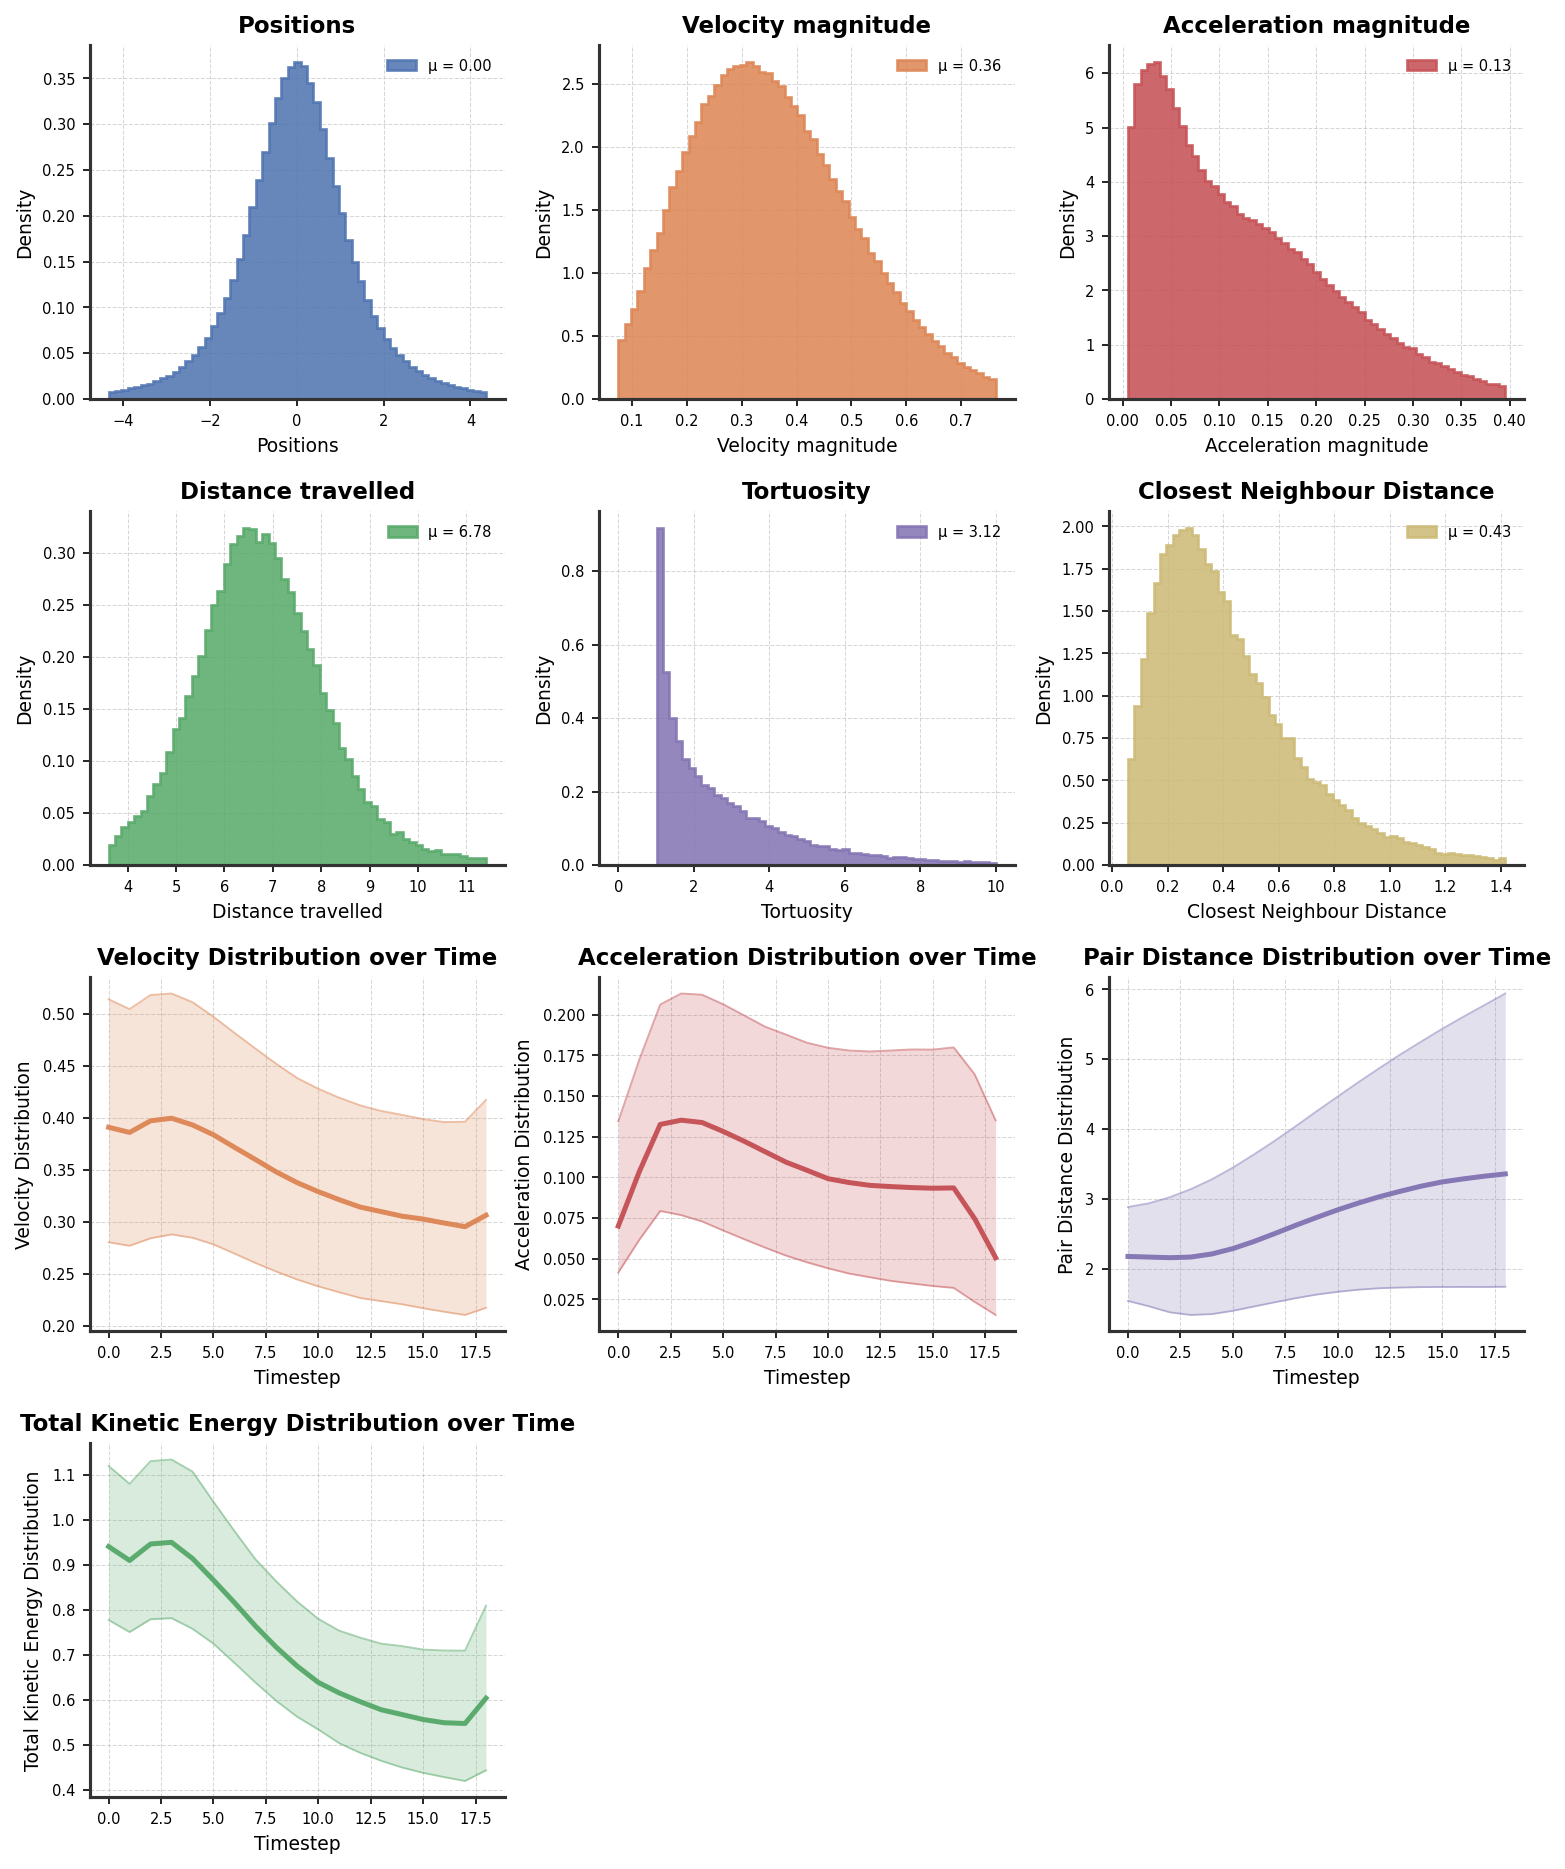

In [6]:
dt = 1  # Time step size

# Positions shape: (#samples, #time_steps, #particles, 3)
positions = np.stack([sample.x[:, :, :3].numpy() for sample in gravity_dataset], axis=0).transpose(0, 2, 1, 3)
# Use the ground truth positions for kinematic calculations
def calculate_kinematics(positions, dt):
    # Positions shape: (#samples, #time_steps, #particles, 3)
    velocities = np.gradient(positions, dt, axis=1)  # Velocities as differences in positions
    accelerations = np.gradient(velocities, dt, axis=1)  # Accelerations as differences in velocities
    vel_magnitudes = np.linalg.norm(velocities, axis=-1)  # Magnitudes of velocities
    acc_magnitudes = np.linalg.norm(accelerations, axis=-1)  # Magnitudes of accelerations

    pairwise_diff = positions[:, :, :, None, :] - positions[:, :, None, :, :]
    pairwise_dist = np.linalg.norm(pairwise_diff, axis=-1)  # (#samples, #time_steps, #particles, #particles)

    arc_lengths = np.sum(vel_magnitudes, axis=1) * dt  # Arc lengths as the sum of velocity magnitudes over time

    tortuosity = arc_lengths / np.linalg.norm(positions[:, -1] - positions[:, 0], axis=-1)  # Tortuosity as the ratio of arc length to straight-line distance

    iu, ju = np.triu_indices(positions.shape[2], k=1)
    pairwise_dist_ij = pairwise_dist[:, :, iu, ju]  # (#samples, #time_steps, #pairs)

    closest_distances = np.min(pairwise_dist_ij, axis=-1)  # Closest distance between any two particles at each time step

    total_kinetic_energy = 0.5 * np.sum(vel_magnitudes**2, axis=-1)  # Total kinetic energy for each sample and time step

    return {
        "velocities": velocities,
        "accelerations": accelerations,
        "vel_magnitudes": vel_magnitudes,
        "acc_magnitudes": acc_magnitudes,
        "distances": pairwise_dist_ij,
        "arc_lengths": arc_lengths,
        "tortuosity": tortuosity,
        "closest_distances": closest_distances,
        "total_kinetic_energy": total_kinetic_energy
    }

properties = calculate_kinematics(positions, dt)


hist_names = ['Positions', 'Velocity magnitude', 'Acceleration magnitude', 'Distance travelled', 'Tortuosity', 'Closest Neighbour Distance']
hist_values = [positions, properties['vel_magnitudes'], properties['acc_magnitudes'], properties['arc_lengths'], properties['tortuosity'], properties['closest_distances']]
hist_colors = ['#4C72B0', '#DD8452', '#C44E52', '#55A868', '#8172B2', '#CCB974']

line_names = ['Velocity Distribution', 'Acceleration Distribution', 'Pair Distance Distribution', 'Total Kinetic Energy Distribution', 'Closest Neighbour Distance Distribution']
line_values = [properties['vel_magnitudes'], properties['acc_magnitudes'], properties['distances'], properties['total_kinetic_energy']]
line_colors = ['#DD8452', '#C44E52', '#8172B2', '#55A868']

%matplotlib inline
fig, axs = plot_kinematics_summary(hist_values, hist_names, hist_colors,
                                    line_values, line_names, line_colors, hist_ranges=[None, None, None, None, (0.0, 10), None])
plt.show()

## Chaotic Systems

To motive the use of generative surrogates, let's look at the evolution of the gravitational system for 2 almost equal intial positions and velocities.

![SegmentLocal](figures/chaotic_divergence.gif)

As we can see, even though the 2 systems start in an almost identical state, their trajectories quickly start diverging and completely seperate around halfway, looking at the plot of total distance between starting pairs on the right.

This sensitive dependence on initial conditions and inpredictability of the future are classical properties of chaotic systems.

## From deterministic to generative surrogates

In practice we never know the state of a system exactly. Frames are subsampled, numbers have finite precision, and during an autoregressive rollout the model feeds its own slightly wrong predictions back in. In a chaotic system such a small error $\delta X^0$ grows roughly exponentially:

$$\|\delta X^t\| \approx e^{\lambda t}\,\|\delta X^0\|,$$

where $\lambda > 0$ is something called the largest [Lyapunov exponent](https://en.wikipedia.org/wiki/Lyapunov_exponent), quantifying divergence in the phase space. The future is therefore best described by a **distribution** over plausible trajectories rather than a single one.

This is a problem for the deterministic surrogates from Practical 2. A model trained with the MSE loss, where $X$ denotes all state information at time $t$ and $V^t$ all the velocities at time $t$, 

$$\mathcal{L}_{\text{MSE}}(\theta) = \mathbb{E}\Big[\big\|f_\theta(X^t) - V^{t+1}\big\|^2\Big]$$

is optimal when it predicts the conditional mean $f_\theta^*(X^t) = \mathbb{E}\big[V^{t+1} \mid X^t\big]$. When several futures are plausible, this mean is an average of all of them. That average is typically overly smooth and does not correspond to any physically realizable trajectory. A **generative** surrogate instead attempts to learn the full conditional distribution $p(V^{t+1} \mid X^t)$ and draws sharp, realistic samples from it.

So, let's train both a deterministic one-step autoregressive model using what we learned from Practical 2 and a generative model one-step autoregressive model using Flow Matching introduced in Practical 3 and compare them.

## One-step autoregressive flow matching

We now use flow matching, from Practical 3, to learn the conditional distribution $p(V^{t+1} \mid X^t)$.

**What we generate and what we condition on.**
- **Condition:** the current state $X^t$ of all $N$ bodies, meaning their positions and velocities (`x_t`, shape $N \times 6$).
- **Target:** the velocities at the next timestep, $x_1 = V^{t+1}$ (`x_1`, shape $N \times 3$).
- **Prior:** samples from a simple Gaussian, $x_0 \sim \mathcal{N}(0, \sigma^2=0.1)$ (`x_0`).

We write the flow time as $\tau \in [0, 1]$, as a **subscript**. At $\tau = 0$ we have noise, and at $\tau = 1$ we have data. The physical time $t$ is always written as a **superscript**.

**Training.** We pick a random $\tau \sim \mathcal{U}(0, 1)$ per graph and interpolate linearly between prior and target:

$$x_\tau = (1 - \tau)\,x_0 + \tau\,x_1 \qquad \texttt{(x\_tau)}$$

Along this straight path, the direction from noise to data is simply $u = x_1 - x_0$ (`u`). The network $v_\theta$ (`DenoisingGNN`) sees the noisy velocities, the flow time and the current state, and learns to predict this direction:

$$\mathcal{L}_{\text{CFM}}(\theta) = \mathbb{E}_{\tau,\, x_0,\, (X^t, x_1)}\Big[\big\|v_\theta(x_\tau, \tau, X^t) - (x_1 - x_0)\big\|^2\Big]$$

The flow time $\tau$ is given to the network as a sinusoidal embedding, and the interactions between bodies are handled by message passing, just like in the deterministic GNN.

**Generation.** To sample $V^{t+1}$, we start from fresh noise $x_0$ and follow the learned vector field from $\tau = 0$ to $\tau = 1$ with $S$ Euler steps of size $\Delta\tau = 1/S$:

$$x_{\tau + \Delta\tau} = x_\tau + \Delta\tau\; v_\theta(x_\tau, \tau, X^t)$$

The final $x_1$ is one sample of the next velocities $V^{t+1}$. We add these velocities to the current positions to get the positions at $t+1$, recompute the edge features, and repeat for the next timestep. Every call draws new noise, so repeating the rollout gives different, equally plausible trajectories.

Note that "velocity" now has two meanings: the physical velocities of the bodies ($x_\tau$), and the *vector field* $v_\theta$ that tells us how to move from noise to data during generation. Keep them apart!

This is the code for the deterministic one-step autoregressive model, from Practical 2

In [7]:
class NeuralMessagePassingLayer(nn.Module):
    def __init__(self, in_features, in_edge_features, hidden_dim, out_features):
        super().__init__()
        self.message_mlp = nn.Sequential(
            nn.Linear(2* in_features + in_edge_features, hidden_dim),
            nn.SiLU(),
            nn.Linear(hidden_dim, hidden_dim),
        )
        self.node_mlp = nn.Sequential(
            nn.Linear(in_features + hidden_dim, hidden_dim),
            nn.SiLU(),
            nn.Linear(hidden_dim, out_features),
        )

    def forward(self, x, edge_index, edge_attr):
        """
        x:          (B*N, in_features)
        edge_index: (2, B*E) where E is the number of edges
        edge_attr:  (B*E, in_edge_features) edge attributes
        """
        source_nodes, target_nodes = edge_index  
        messages = self.message_mlp(T.cat([x[source_nodes], x[target_nodes], edge_attr], dim=-1))

        aggregated_messages = T.zeros(x.size(0), messages.size(-1), device=x.device)
        aggregated_messages.index_reduce_(0, target_nodes, messages, reduce="mean", include_self=False)

        x = T.cat([x, aggregated_messages], dim=-1)
        x = self.node_mlp(x)
    
        return x


class GNN(nn.Module):
    def __init__(self, input_dim, hidden_dim, output_dim, in_edge_features=0):
        super().__init__()
        self.projection = nn.Linear(input_dim, hidden_dim)

        self.message_passing1 = NeuralMessagePassingLayer(
            hidden_dim, in_edge_features, hidden_dim, hidden_dim
        )
        self.message_passing2 = NeuralMessagePassingLayer(
            hidden_dim, in_edge_features, hidden_dim, output_dim
        )

    def forward(self, x, edge_index, edge_attr):
        x = self.projection(x)
        x = self.message_passing1(x, edge_index, edge_attr)
        x = F.silu(x)
        x = self.message_passing2(x, edge_index, edge_attr)

        return x

class DeterministicParticleModel(L.LightningModule):
    def __init__(self, model, learning_rate=1e-3):
        super().__init__()
        self.model = model
        self.learning_rate = learning_rate

    def forward(self, *args, **kwargs):
        return self.model(*args, **kwargs)

    def _step(self, batch):
        inputs = batch.x[..., :6]  # Shape: (batch_size, num_particles, 6)
        targets = batch.y[..., 3:6]  # Shape: (batch_size, num_particles, 3)
        outputs = self(inputs, batch.edge_index, batch.edge_attr)  # Shape: (batch_size, num_particles, 3)
        loss = F.mse_loss(outputs, targets)  # Mean Squared Error loss
        return loss

    def training_step(self, batch, batch_idx):
        loss = self._step(batch)
        self.log("train_loss", loss, on_step=False, on_epoch=True, prog_bar=True)
        return loss

    def validation_step(self, batch, batch_idx):
        loss = self._step(batch)
        self.log("val_loss", loss, on_step=False, on_epoch=True, prog_bar=True)
        return loss

    def predict_step(self, batch, batch_idx):
        rollout = T.zeros_like(batch.x)  # Initialize all inputs/outputs
        rollout[:, 0] = batch.x[:, 0]  # Get t=1 of trajectory for first prediction input
        for t in range(0, rollout.shape[1] - 1):
            old_positions = rollout[:, t, :3]

            model_input = rollout[:, t]  # Use model's own prediction for next input

            new_velocities = self(model_input, batch.edge_index, batch.edge_attr)
            new_positions = old_positions + new_velocities
            
            # Recompute edge attributes for the next timestep based on the new positions
            batch.edge_attr = edge_features(new_positions, batch.edge_index)
            
            rollout[:, t + 1, :6] = T.cat([new_positions, new_velocities], dim=-1)

        rollout, _ = to_dense_batch(rollout, batch.batch)
        return rollout

    def configure_optimizers(self):
        return T.optim.Adam(self.parameters(), lr=self.learning_rate)

Here we define the one-step flow matching model

In [8]:
class DenoisingGNN(nn.Module):
    def __init__(self, input_dim, tau_dim, cond_dim, hidden_dim, output_dim, in_edge_features=0):
        super().__init__()
        self.tau_dim = tau_dim
        self.encoder = nn.Sequential(
            nn.Linear(input_dim  + cond_dim + tau_dim, hidden_dim),
            nn.SiLU(),
            nn.Linear(hidden_dim, hidden_dim),
            nn.SiLU()
        )

        self.message_passing1 = NeuralMessagePassingLayer(
            hidden_dim, in_edge_features, hidden_dim, hidden_dim
        )
        self.message_passing2 = NeuralMessagePassingLayer(
            hidden_dim, in_edge_features, hidden_dim, hidden_dim
        )
        self.decoder = nn.Sequential(nn.Linear(hidden_dim, hidden_dim), nn.SiLU(), nn.Linear(hidden_dim, output_dim))

    def timestep_embedding(self, timesteps, dim, max_period=10000):
        """Create sinusoidal timestep embeddings."""
        half = dim // 2
        freqs = T.exp(-math.log(max_period) * T.arange(half, device=timesteps.device, dtype=T.float32) / half)
        args = timesteps[:, None].float() * freqs[None]
        embedding = T.cat([args.cos(), args.sin()], dim=-1)
        if dim % 2:
            embedding = F.pad(embedding, (0, 1))
        return embedding

    def forward(self, x_tau, tau, x_t, edge_index, edge_attr):
        """
        Forward pass of the denoising GNN.

        Args:
            x_tau: Velocities at time tau (B*N, 3)
            tau: Noise level (B*N)
            x_t: State information at time t (B*N, 6)
            edge_index: Edge indices (2, num_edges)
            edge_attr: Edge attributes (num_edges, in_edge_features)

        Returns:
            Predicted change in velocities (B*N, 3)
        """

        tau_emb = self.timestep_embedding(tau*1000, self.tau_dim)

        x = self.encoder(T.cat([x_tau, x_t, tau_emb], dim=-1))

        x = self.message_passing1(x, edge_index, edge_attr)
        x = F.silu(x)
        x = self.message_passing2(x, edge_index, edge_attr)
        x = self.decoder(x)
        return x

class ProbabilisticParticleModel(DeterministicParticleModel):
    def __init__(self, model, denoising_steps=10, learning_rate=1e-3, t_start=0, num_samples=1):
        super().__init__(model, learning_rate)
        self.denoising_steps = denoising_steps
        self.t_start = t_start
        self.num_samples = num_samples

    def _step(self, batch):
        B, N = batch.batch_size, batch.num_nodes // batch.batch_size
        x_t = batch.x  # Ground truth positions and velocities at time t  Shape: (B*N, 6)
        x_1 = batch.y[..., 3:6]  # Ground truth velocities at t+1  Shape: (B*N, 3)
        
        tau = T.rand(B, device=x_t.device)  # Random noise amount for each mini-batch graph  Shape: (B,)
        tau = tau.repeat_interleave(N).view(B * N, 1)  # Expand tau to match the number of particles  Shape: (B*N, 1)

        x_0 = T.randn_like(x_1) * math.sqrt(0.1)  # Sample prior velocities from N(0, 0.1)

        x_tau = x_0 * (1 - tau) + x_1 * tau  # Interpolate linearly between x_0 and x_1 based on tau

        u = x_1 - x_0  # Compute the target vectors for the model to predict

        v = self(x_tau, tau[:, 0], x_t, batch.edge_index, batch.edge_attr)  # Predict change in velocities to denoise (B*N, 3)

        loss = F.mse_loss(v, u)  # Mean Squared Error loss

        return loss

    def predict_step(self, batch, batch_idx):
        initial_edge_attr = batch.edge_attr.clone()  # Store the initial edge attributes
        samples = []
        for _ in range(self.num_samples):
            batch.edge_attr = initial_edge_attr.clone()
            samples.append(self._predict_single_sample(batch))
        return T.stack(samples, dim=1) # Shape (B, num_samples, N, T, 6)

    def _predict_single_sample(self, batch):
        B, N = batch.batch_size, batch.num_nodes // batch.batch_size
        rollout = T.zeros_like(batch.x)  # Initialize all inputs/outputs
        rollout[:, self.t_start] = batch.x[:, self.t_start]  # Get t=1 of trajectory for first prediction input
        if self.t_start > 0:
            rollout[:, :self.t_start] = batch.x[:, :self.t_start]  # Copy the initial timesteps if t_start > 0
            batch.edge_attr = edge_features(rollout[:, self.t_start, :3], batch.edge_index)  # Compute edge attributes for the first timestep

        noise_steps = T.linspace(0.0, 1.0, self.denoising_steps + 1, device=rollout.device)  # Noise levels for denoising

        for t in range(self.t_start, rollout.shape[1] - 1):
            old_positions = rollout[:, t, :3]
            old_velocities = rollout[:, t, 3:6]
            x_t = rollout[:, t]  # System state at time t (positions and velocities)

            x_0 = T.randn_like(old_velocities) * math.sqrt(0.1)  # Sample prior velocities from N(0, 0.1)
            x_tau = x_0.clone()  # Initialize x_tau with the prior velocities

            for i in range(self.denoising_steps):  # Euler integration steps for denoising
                tau = noise_steps[i].repeat(B * N)  # Current noise level for all particles

                v = self(x_tau, tau, x_t, batch.edge_index, batch.edge_attr)  # Predict change in velocities to denoise

                x_tau = x_tau + (noise_steps[i+1] - noise_steps[i]) * v  # Euler integration step

            new_velocities = x_tau  # The denoised velocities are the new velocities
            new_positions = old_positions + new_velocities  # Update positions based on the denoised velocities
            
            # Recompute edge attributes for the next timestep based on the new positions
            batch.edge_attr = edge_features(new_positions, batch.edge_index)
            
            rollout[:, t + 1, :6] = T.cat([new_positions, new_velocities], dim=-1)

        rollout, _ = to_dense_batch(rollout, batch.batch)
        return rollout

class LossHistory(L.Callback):
    def __init__(self):
        self.train_loss, self.val_loss = [], []
    def on_train_epoch_end(self, trainer, pl_module):
        self.train_loss.append(trainer.callback_metrics.get("train_loss").item())
    def on_validation_epoch_end(self, trainer, pl_module):
        self.val_loss.append(trainer.callback_metrics.get("val_loss").item())

def plot_loss_curves(train_loss, val_loss, title="Loss Curves"):
    plt.figure(figsize=(8, 5))
    plt.plot(train_loss, label="Train Loss", color="tab:blue")
    plt.plot(val_loss, label="Validation Loss", color="tab:orange")
    plt.title(title)
    plt.xlabel("Epochs")
    plt.ylabel("Loss")
    plt.legend()
    plt.grid(alpha=0.5)
    plt.show()

state_dim = 6  # 3 for position, 3 for velocity
tau_dim = 16  # Dimension of the sinusoidal timestep embedding
target_dim = 3  # Predicting 3D velocity changes
edge_feats_dim = 4  # Edge features: displacement (3D) + distance (1D)
hidden_dim = 64  # Hidden dimension for the GNN layers

In [9]:
gnn = GNN(input_dim=state_dim, hidden_dim=hidden_dim, output_dim=target_dim, in_edge_features=edge_feats_dim)
deterministic_model = DeterministicParticleModel(model=gnn, learning_rate=1e-3)

loss_history_gnn = LossHistory()
trainer1 = L.Trainer(max_epochs=30, accelerator="auto", callbacks=[loss_history_gnn], limit_train_batches=300, limit_val_batches=100, logger=False, enable_checkpointing=False)
trainer1.fit(deterministic_model, datamodule=step_datamodule)

rollouts_gnn = trainer1.predict(deterministic_model, datamodule=traj_datamodule)
predicted_positions_gnn = T.cat(rollouts_gnn, dim=0).transpose(1,2).numpy()[..., :3]

GPU available: True (cuda), used: True
TPU available: False, using: 0 TPU cores
💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
You are using a CUDA device ('NVIDIA GeForce RTX 4060 Laptop GPU') that has Tensor Cores. To properly utilize them, you should set `torch.set_float32_matmul_precision('medium' | 'high')` which will trade-off precision for performance. For more details, read https://pytorch.org/docs/stable/generated/torch.set_float32_matmul_precision.html#torch.set_float32_matmul_precision
LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]

  | Name  | Type | Params | Mode  | FLOPs
-----------------------------------------------
0 | model | GNN  | 46.7 K | train | 0    
-----------------------------------------------
46.7 K    Trainable params
0         Non-trainable params
46.7 K    Total params
0.187     T

Sanity Checking: |          | 0/? [00:00<?, ?it/s]

c:\Users\Saber\.conda\envs\DEEPLEARNING\Lib\site-packages\lightning\pytorch\trainer\connectors\data_connector.py:434: The 'val_dataloader' does not have many workers which may be a bottleneck. Consider increasing the value of the `num_workers` argument` to `num_workers=23` in the `DataLoader` to improve performance.
c:\Users\Saber\.conda\envs\DEEPLEARNING\Lib\site-packages\lightning\pytorch\utilities\data.py:79: Trying to infer the `batch_size` from an ambiguous collection. The batch size we found is 160. To avoid any miscalculations, use `self.log(..., batch_size=batch_size)`.
c:\Users\Saber\.conda\envs\DEEPLEARNING\Lib\site-packages\lightning\pytorch\trainer\connectors\data_connector.py:434: The 'train_dataloader' does not have many workers which may be a bottleneck. Consider increasing the value of the `num_workers` argument` to `num_workers=23` in the `DataLoader` to improve performance.


Training: |          | 0/? [00:00<?, ?it/s]

Validation: |          | 0/? [00:00<?, ?it/s]

...

Validation: |          | 0/? [00:00<?, ?it/s]

Validation: |          | 0/? [00:00<?, ?it/s]

Validation: |          | 0/? [00:00<?, ?it/s]

`Trainer.fit` stopped: `max_epochs=30` reached.
LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]
c:\Users\Saber\.conda\envs\DEEPLEARNING\Lib\site-packages\lightning\pytorch\trainer\connectors\data_connector.py:434: The 'predict_dataloader' does not have many workers which may be a bottleneck. Consider increasing the value of the `num_workers` argument` to `num_workers=23` in the `DataLoader` to improve performance.


Predicting: |          | 0/? [00:00<?, ?it/s]

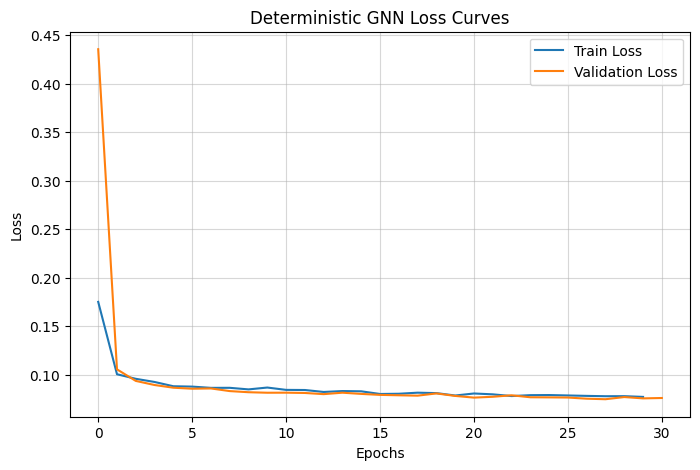

In [10]:
plot_loss_curves(loss_history_gnn.train_loss, loss_history_gnn.val_loss, title="Deterministic GNN Loss Curves")

In [11]:
denoising_gnn = DenoisingGNN(input_dim=target_dim, tau_dim=tau_dim, cond_dim=state_dim, hidden_dim=hidden_dim, output_dim=target_dim, in_edge_features=edge_feats_dim)
generative_model = ProbabilisticParticleModel(model=denoising_gnn, denoising_steps=20, learning_rate=5e-4, t_start=0, num_samples=20)

loss_history_d_gnn = LossHistory()
trainer2 = L.Trainer(max_epochs=50, accelerator="auto", callbacks=[loss_history_d_gnn], limit_train_batches=300, limit_val_batches=100, logger=False, enable_checkpointing=False)
trainer2.fit(generative_model, datamodule=step_datamodule)

rollouts_d_gnn = trainer2.predict(generative_model, datamodule=traj_datamodule)
predicted_positions_d_gnn = T.cat(rollouts_d_gnn, dim=0).transpose(2,3).numpy()[..., :3]

GPU available: True (cuda), used: True
TPU available: False, using: 0 TPU cores
💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]

  | Name  | Type         | Params | Mode  | FLOPs
-------------------------------------------------------
0 | model | DenoisingGNN | 60.4 K | train | 0    
-------------------------------------------------------
60.4 K    Trainable params
0         Non-trainable params
60.4 K    Total params
0.241     Total estimated model params size (MB)
28        Modules in train mode
0         Modules in eval mode
0         Total Flops


Sanity Checking: |          | 0/? [00:00<?, ?it/s]

Training: |          | 0/? [00:00<?, ?it/s]

Validation: |          | 0/? [00:00<?, ?it/s]

Validation: |          | 0/? [00:00<?, ?it/s]

...

Validation: |          | 0/? [00:00<?, ?it/s]

Validation: |          | 0/? [00:00<?, ?it/s]

Validation: |          | 0/? [00:00<?, ?it/s]

`Trainer.fit` stopped: `max_epochs=50` reached.
LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]


Predicting: |          | 0/? [00:00<?, ?it/s]

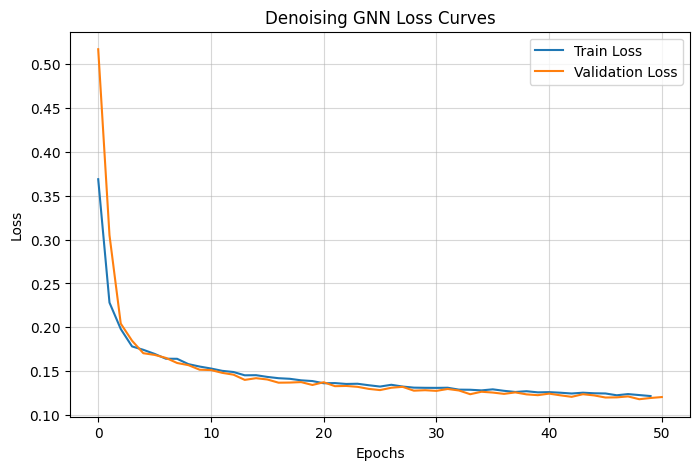

In [12]:
plot_loss_curves(loss_history_d_gnn.train_loss, loss_history_d_gnn.val_loss, title="Denoising GNN Loss Curves")

### Comparing the deterministic surrogate with the generative surrogate

We now compare the deterministic GNN with the flow matching GNN on the **coarse trajectories** (every 6th frame). Both models start from the true state at $t = 0$ and are rolled out autoregressively up to the final frame $T$. For the generative model we draw $M = 20$ samples per initial condition.

**Notation.** $\mathbf{p}_i^t$ is the true position of body $i$ at frame $t$. $\hat{\mathbf{p}}_i^t$ is the deterministic prediction, and $\hat{\mathbf{p}}_i^{t,(m)}$ is the $m$-th generative sample, with $m = 1, \dots, M$.

#### Pointwise errors

The **displacement error** measures how far a predicted body is from where it really is: $e_i^t = \big\|\hat{\mathbf{p}}_i^t - \mathbf{p}_i^t\big\|.$

- **ADE** (Average Displacement Error) averages this error over all bodies and frames: $\text{ADE} = \frac{1}{(T+1)N}\sum_{t=0}^{T}\sum_{i=1}^{N} e_i^t$.
- **FDE** (Final Displacement Error) looks only at the last frame: $\text{FDE} = \frac{1}{N}\sum_{i=1}^{N} e_i^T$.

For the generative model we compute both metrics per sample and then average over the $M$ samples. The result is the expected error of *one* randomly drawn future. All metrics are averaged over the test scenes.

*Be careful when interpreting ADE and FDE.* The MSE-trained model predicts the *average* of all plausible futures. This average is a "safe" guess that lies close to every outcome, even though no physical system would follow it. A generative sample commits to one sharp future. A perfect generative model therefore still has a *higher* ADE than the mean predictor, explained below in a seperate plot.

**Best-of-$M$ ADE/FDE** asks whether the true future is among the futures the model considers plausible:

$$\text{minADE}_M = \min_m \text{ADE}^{(m)}, \qquad \text{minFDE}_M = \min_m \text{FDE}^{(m)},$$

reported as mean. The two minima are taken separately, so the best sample for FDE need not be the best sample for ADE. These metrics reward spread: a model that scatters its samples widely can score well. Always read them together with the distributions below.

#### Distributional quantities

| Quantity | Definition | Intuition | Plot |
|---|---|---|---|
| Positions | components of $\mathbf{p}_i^t$ | how spread out the system is | histogram |
| Velocity magnitude | $\|\mathbf{v}_i^t\|$ | speed of a body | histogram, over time |
| Acceleration magnitude | $\|\mathbf{a}_i^t\|$ | strength of the gravitational pull, the long tail comes from close encounters | histogram, over time |
| Distance travelled | $L_i = \sum_{t} \|\mathbf{v}_i^t\|\,\Delta t$ | path length of a body, averaging futures shortens it | histogram |
| Tortuosity | $L_i \,/\, \|\mathbf{p}_i^T - \mathbf{p}_i^0\|$ | $1$ for a straight line, larger for curvier paths | histogram |
| Closest neighbour distance | $d_{\min}^t = \min_{i<j} \|\mathbf{p}_i^t - \mathbf{p}_j^t\|$ | the closest pair in the whole system, probes close encounters | histogram, over time |
| Total kinetic energy | $E_{\text{kin}}^t = \tfrac{1}{2}\sum_i \|\mathbf{v}_i^t\|^2$ | overall energy of the system (unit masses), shows energy loss or drift | over time |
| Displacement error | $e_i^t$ | how fast errors grow during the rollout (the ground truth is the zero line) | over time |

**Histograms** show normalised densities pooled over all scenes, frames and bodies, the legend gives the mean $\mu$. 

**Plots over time** show the median (line) and the 25th–75th percentile band at each frame. For the generative model, all $M$ samples are pooled, so we compare the *whole ensemble* with the true data distribution.

A good generative model should match these distributions even where its ADE is higher. An over-smoothed deterministic model typically shows lower speeds, shorter distances travelled and fewer large accelerations.

Deterministic GNN ADE: 1.0480, FDE: 1.9718
Generative GNN ADE: 1.2894, FDE: 2.4274
Generative GNN min-20 ADE: 1.0035 ± 0.2085, min-20 FDE: 1.4098 ± 0.3314


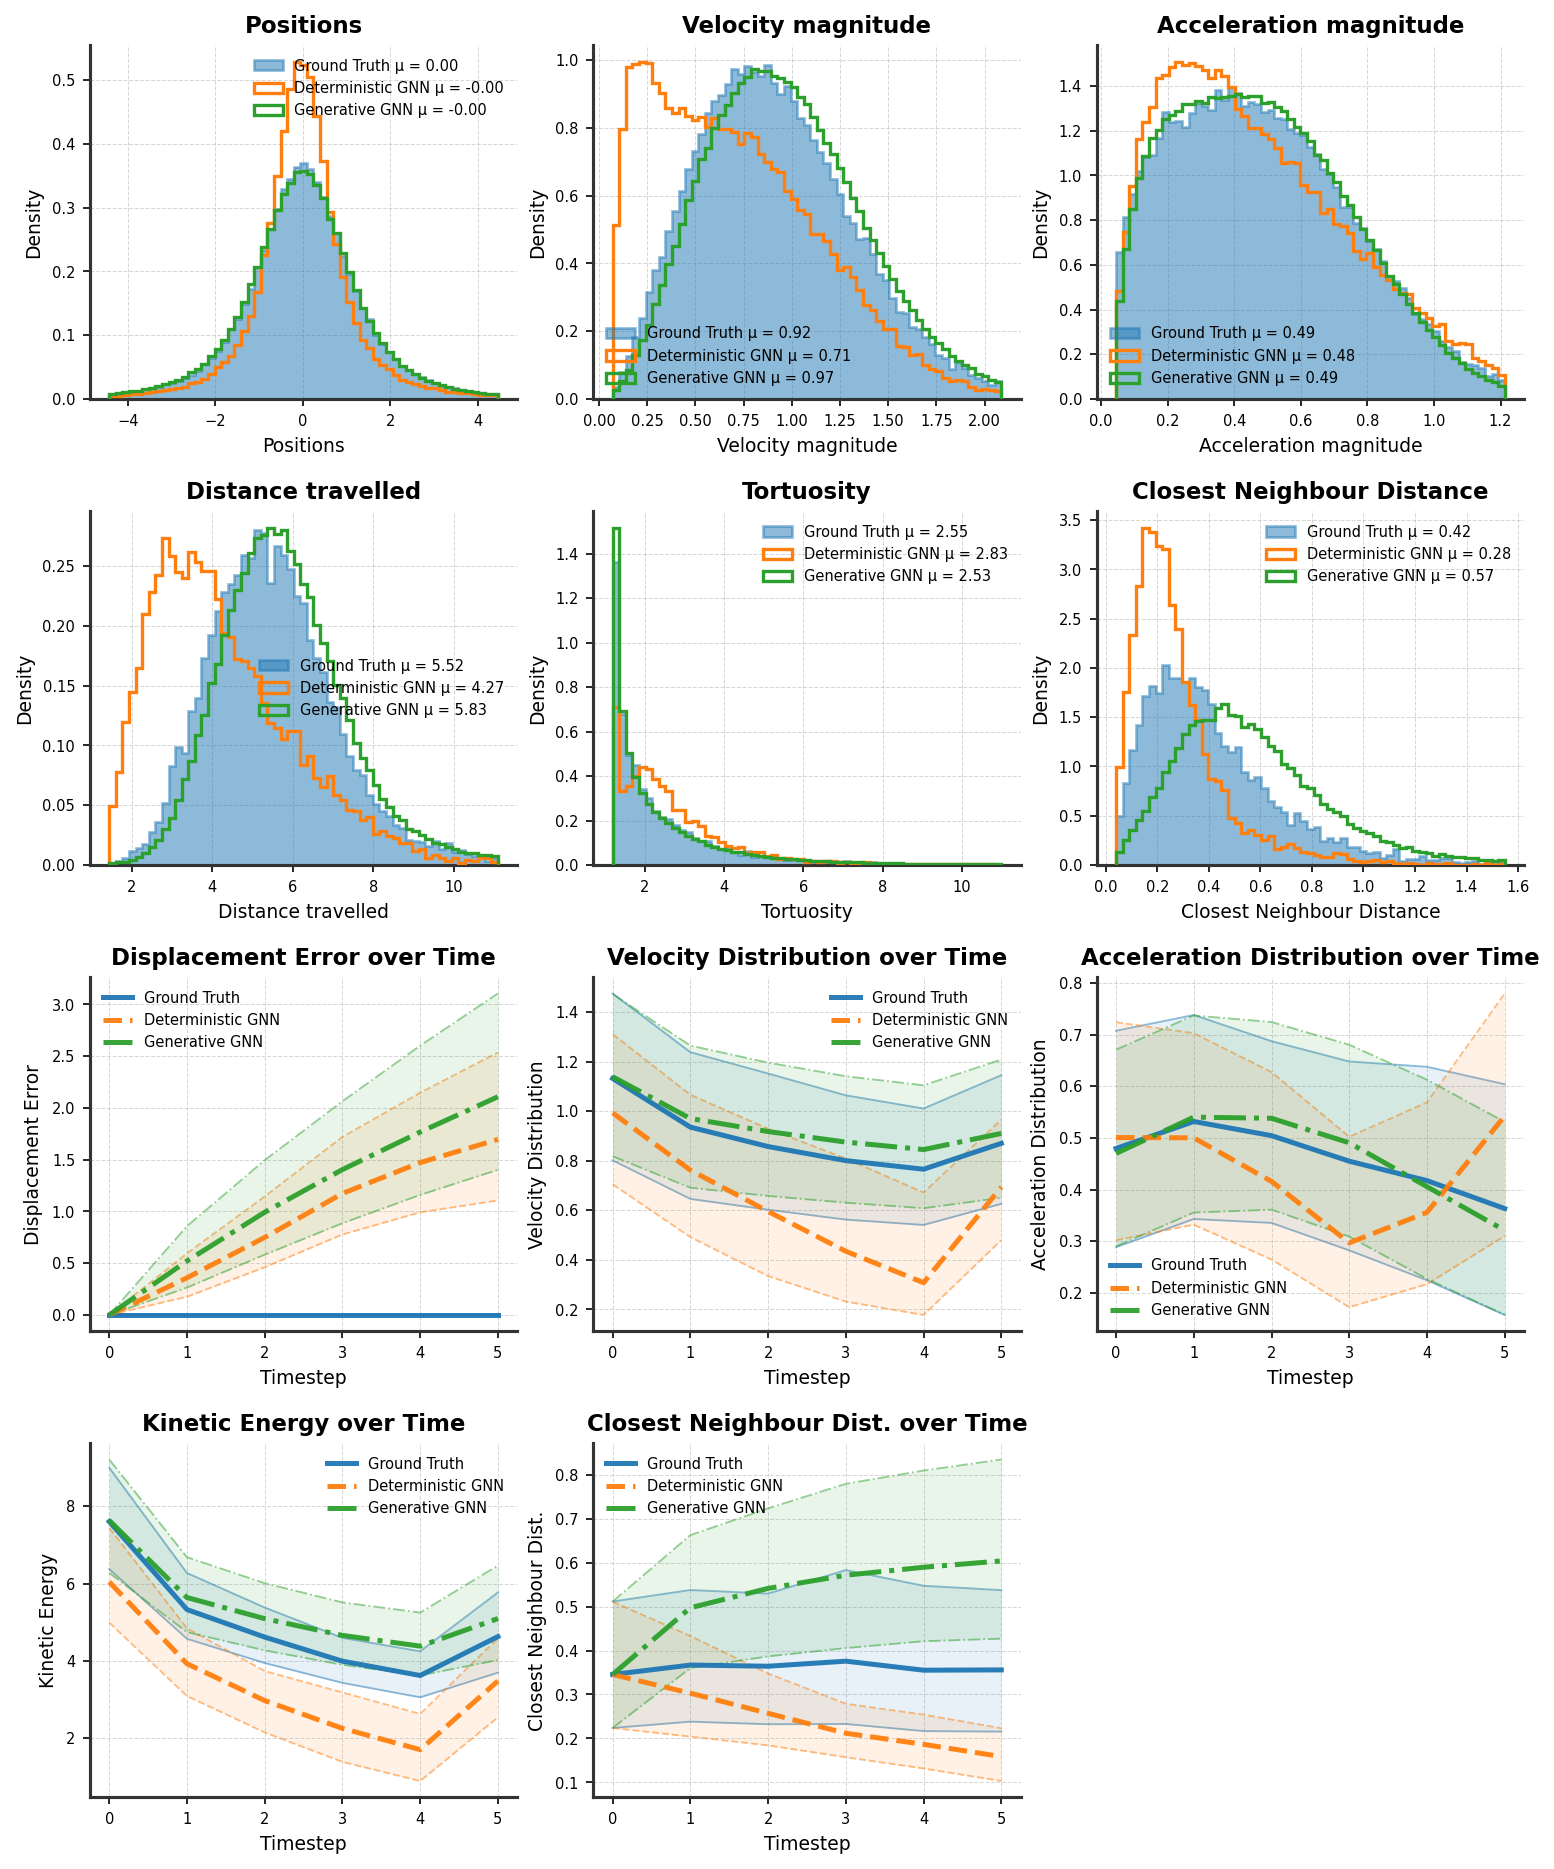

In [13]:
displacement_errors_gnn = np.linalg.norm(predicted_positions_gnn - ground_truth_coarsened_positions, axis=-1)
displacement_errors_d_gnn = np.linalg.norm(predicted_positions_d_gnn - ground_truth_coarsened_positions[:, None], axis=-1)

ADE_gnn = np.mean(displacement_errors_gnn, axis=(1,2))
ADE_d_gnn = np.mean(displacement_errors_d_gnn, axis=(2,3))
FDE_gnn = np.mean(displacement_errors_gnn[:, -1], axis=1)
FDE_d_gnn = np.mean(displacement_errors_d_gnn[:, :, -1], axis=1)
S = displacement_errors_d_gnn.shape[0]
best = np.argmin(ADE_d_gnn, axis=1)                                   # best sample per scene, (S,)
best_errors_d_gnn = displacement_errors_d_gnn[np.arange(S), best]     # (S, T, N)
min_20_ADE_d_gnn = ADE_d_gnn[np.arange(S), best]
min_20_FDE_d_gnn = np.min(FDE_d_gnn, axis=1)

print(f"Deterministic GNN ADE: {np.mean(ADE_gnn):.4f}, FDE: {np.mean(FDE_gnn):.4f}")
print(f"Generative GNN ADE: {np.mean(ADE_d_gnn):.4f}, FDE: {np.mean(FDE_d_gnn):.4f}")
print(f"Generative GNN min-20 ADE: {np.mean(min_20_ADE_d_gnn):.4f} ± {np.std(min_20_ADE_d_gnn):.4f}, min-20 FDE: {np.mean(min_20_FDE_d_gnn):.4f} ± {np.std(min_20_FDE_d_gnn):.4f}")

pred_gnn_kin = calculate_kinematics(predicted_positions_gnn, dt)
pred_d_gnn_kin = calculate_kinematics(predicted_positions_d_gnn.reshape(-1, *predicted_positions_d_gnn.shape[2:]), dt)
gt_kin = calculate_kinematics(ground_truth_coarsened_positions, dt)

hist_names = ["Positions", "Velocity magnitude", "Acceleration magnitude", "Distance travelled", "Tortuosity", "Closest Neighbour Distance"]
hist_values = [(ground_truth_coarsened_positions, predicted_positions_gnn, predicted_positions_d_gnn),
               (gt_kin['vel_magnitudes'], pred_gnn_kin['vel_magnitudes'], pred_d_gnn_kin['vel_magnitudes']),
               (gt_kin['acc_magnitudes'], pred_gnn_kin['acc_magnitudes'], pred_d_gnn_kin['acc_magnitudes']),
               (gt_kin['arc_lengths'], pred_gnn_kin['arc_lengths'], pred_d_gnn_kin['arc_lengths']),
               (gt_kin['tortuosity'], pred_gnn_kin['tortuosity'], pred_d_gnn_kin['tortuosity']),
               (gt_kin['closest_distances'], pred_gnn_kin['closest_distances'], pred_d_gnn_kin['closest_distances'])]
cmap = plt.get_cmap("tab10")
hist_colors = [(cmap(0), cmap(1), cmap(2)),
               (cmap(0), cmap(1), cmap(2)),
               (cmap(0), cmap(1), cmap(2)),
               (cmap(0), cmap(1), cmap(2)),
               (cmap(0), cmap(1), cmap(2)),
               (cmap(0), cmap(1), cmap(2))]

line_names = ["Displacement Error", "Velocity Distribution", "Acceleration Distribution", "Kinetic Energy", "Closest Neighbour Dist."]
line_values = [(np.zeros_like(displacement_errors_gnn), displacement_errors_gnn, displacement_errors_d_gnn.reshape(-1, *displacement_errors_d_gnn.shape[2:])),
               (gt_kin['vel_magnitudes'], pred_gnn_kin['vel_magnitudes'], pred_d_gnn_kin['vel_magnitudes']),
               (gt_kin['acc_magnitudes'], pred_gnn_kin['acc_magnitudes'], pred_d_gnn_kin['acc_magnitudes']),
               (gt_kin['total_kinetic_energy'], pred_gnn_kin['total_kinetic_energy'], pred_d_gnn_kin['total_kinetic_energy']),
               (gt_kin['closest_distances'], pred_gnn_kin['closest_distances'], pred_d_gnn_kin['closest_distances'])]
line_colors = [(cmap(0), cmap(1), cmap(2)),
               (cmap(0), cmap(1), cmap(2)),
               (cmap(0), cmap(1), cmap(2)),
                (cmap(0), cmap(1), cmap(2)),
                (cmap(0), cmap(1), cmap(2))]

%matplotlib inline
whatever = plot_kinematics_summary(hist_values, hist_names, hist_colors,
                                    line_values, line_names, line_colors, model_labels=["Ground Truth", "Deterministic GNN", "Generative GNN"]),

## **Questions**
### How would the deterministic and generative one-step models compare on data with higher time resolution? What happens to $p(V^{t+1} \mid X^t)$? Does the uncertainty over the full trajectory change?

### Is there a way to evaluate how well the generative model has learned the actual uncertainty in the system, if we have access to the real simulator? 

![SegmentLocal](figures/perturbed_ensemble_model_vs_simulator.png)

## What is time bundling and why?

So far, our models map one frame to the next: $\hat{X}^{t+1} = f_\theta(\hat{X}^t)$. Generating $T$ frames therefore requires $T$ sequential model calls ($T \cdot S$ network evaluations for flow matching with $S$ Euler steps). Every call adds a small error that is fed back into the next one.

With **time bundling**, the model instead maps a window of $H$ observed frames to a bundle of $K$ future frames at once:

$$\hat{X}^{t+1:t+K} = f_\theta\big(X^{t-H+1:t}\big).$$

![SegmentLocal](figures/time_bundling.png)

This has three benefits:

1. **Less error accumulation.** Only $\lceil T/K \rceil$ calls are needed instead of $T$, so the model feeds its own predictions back in much less often.
2. **Efficiency.** For flow matching, every call costs $S$ network evaluations. The total cost drops from $T \cdot S$ to $\lceil T/K \rceil \cdot S$.
3. **Temporal context.** The model sees a history of frames and predicts a coherent block of future frames. This lets it capture correlations over time, instead of treating each step independently.

For time bundling, we go back to **finer trajectories**: we now keep every 2nd frame of the simulation instead of every 6th.

## Flow matching with time bundling

Each trajectory has $19$ frames. The model observes the first $H = 6$ frames and generates the remaining $K = 13$ frames in a single call. The flow matching recipe stays the same as before, only the condition and the target change:

$$\text{condition: } X^{0}, \dots, X^{5} \in \mathbb{R}^{6 \times N \times 6}, \qquad \text{target: } x_1 = \big(V^{6}, \dots, V^{18}\big) \in \mathbb{R}^{13 \times N \times 3}.$$

The prior is again Gaussian, $x_0 \sim \mathcal{N}(0, 0.05\, I)$, now for all 13 target frames at once. After generation, we recover the positions by adding up the generated velocities, starting from the last observed position $\mathbf{p}_i^{5}$ of each body $i$:

$$\mathbf{p}_i^{5+k} = \mathbf{p}_i^{5} + \sum_{j=1}^{k} \mathbf{v}_i^{5+j}, \qquad k = 1, \dots, 13.$$

**Space and time.** The model must now capture patterns across **space**, meaning the interactions between bodies, and across **time**, meaning how each body's motion evolves over the window. The GNN handles space through message passing, but it has no mechanism for time. We therefore add a simple component for the time dimension.

**Architecture** (`DenoisingGNNMLP`). For every body $i$, we flatten all its inputs into one vector: the 13 noisy target velocities $x_\tau$, the 6 observed states, and the flow-time embedding. An MLP encoder turns this vector into one hidden embedding per body:

$$\mathbf{h}_i = \text{MLP}_{\text{enc}}\Big(\text{flatten}\big[x_{\tau,i},\; X_i^{0:5},\; \text{emb}(\tau)\big]\Big) \in \mathbb{R}^{d}.$$

Message passing layers then exchange information between bodies, using edge features computed from the positions at the last observed frame. Finally, an MLP decoder maps each $\mathbf{h}_i$ back to the predicted vector field for all 13 target frames, $v_{\theta,i} \in \mathbb{R}^{13 \times 3}$.

**Limitations.** This design is deliberately simple. The MLP has no notion of temporal order or locality, it only works for a fixed window length, and the interactions between bodies are based on their positions at a single frame, even though the bodies move during the window. Finding better ways to model the temporal dimension is part of Assignment 2.

In [14]:
class TrajectoryDataset(ParticleDatasetBase):

    def __init__(self, path, coarsen_factor, H, K):
        super().__init__(path)
        self.coarsen_factor = coarsen_factor
        self.H = H
        self.K = K

    def __len__(self):
        return self.n_simulations

    def __getitem__(self, idx):
        X = self.nodes[idx].transpose(0,1)  # Node features for the current trajectory
        # Shape of X: ( n_nodes, traj_length, n_features)

        # Edge index for a fully connected graph  Shape of edge_idx: (2, n_edges)
        edge_idx = (~T.eye(X.size(0), dtype=T.bool)).nonzero().T

        edge_attr = edge_features(X[:, self.H-1, :3], edge_idx)

        return Data(x=X, edge_index=edge_idx, edge_attr=edge_attr)

class DenoisingGNNMLP(nn.Module):

    def __init__(self, H, K, d=64, tau_dim=16, edge_dim=4, n_layers=3, d_output=3):
        super().__init__()
        self.tau_dim = tau_dim
        self.encoder = nn.Sequential(
            nn.Linear(H * 6 + K * 3 + tau_dim, 2*d),
            nn.SiLU(),
            nn.Linear(2*d, 2*d),
            nn.SiLU(),
            nn.Linear(2*d, d),
            nn.SiLU()
        )

        self.mp_layers = nn.ModuleList([NeuralMessagePassingLayer(d, edge_dim, d, d) for _ in range(n_layers)])

        self.decoder = nn.Sequential(nn.Linear(d, d), nn.SiLU(), nn.Linear(d, d_output * K))

    def timestep_embedding(self, timesteps, dim, max_period=10000):
        """Create sinusoidal timestep embeddings."""
        half = dim // 2
        freqs = T.exp(-math.log(max_period) * T.arange(half, device=timesteps.device, dtype=T.float32) / half)
        args = timesteps[:, None].float() * freqs[None]
        embedding = T.cat([args.cos(), args.sin()], dim=-1)
        if dim % 2:
            embedding = F.pad(embedding, (0, 1))
        return embedding

    def forward(self, X_tau, tau, X_H, edge_index, edge_attr):
        """
        Forward pass of the denoising GNN.

        Args:
            X_tau: Velocities of K target timesteps with noise level tau (B*N, K, 3)
            tau: Noise level (B*N)
            X_H: State information of H observed timesteps (B*N, H, 6)
            edge_index: Edge indices (2, num_edges)
            edge_attr: Edge attributes (num_edges, in_edge_features)

        Returns:
            Predicted change in velocities (B*N, K, 3)
        """

        tau_emb = self.timestep_embedding(tau*1000, self.tau_dim)

        h = self.encoder(T.cat([X_tau.flatten(1, 2), tau_emb, X_H.flatten(1, 2)], dim=-1))

        for layer in self.mp_layers:
            h_new = layer(h, edge_index, edge_attr)
            h = h + F.silu(h_new)  # Residual connection
            h = F.layer_norm(h, (h.size(-1),))

        v = self.decoder(h).view_as(X_tau)  # Reshape to (B*N, K, 3)
        return v


class ProbabilisticTrajectoryModel(ProbabilisticParticleModel):
    def __init__(self, model, denoising_steps=10, learning_rate=1e-3, H=6, K=14, num_samples=10):
        super().__init__(model, denoising_steps, learning_rate)
        self.H = H
        self.K = K
        self.num_samples = num_samples

    def sample_prior(self, shape, X_H):
        return T.randn(shape, device=X_H.device) * math.sqrt(0.05)

    def _step(self, batch):
        B, N, K, H = batch.batch_size, batch.num_nodes // batch.batch_size, self.K, self.H
        X_H = batch.x[:, :H]  # Ground truth positions and velocities at times 0 to H  Shape: (B*N, H, 6)
        X_1 = batch.x[:, H:H + K, 3:6]  # Ground truth velocities at times H to T  Shape: (B*N, K, 3)
        
        tau = T.rand(B, device=X_H.device)  # Random noise amount for each mini-batch graph  Shape: (B,)
        tau = tau.repeat_interleave(N).view(B * N, 1, 1)  # Expand tau to match the number of particles  Shape: (B*N, 1, 1)

        X_0 = self.sample_prior((B * N, K, 3), X_H)  # Sample prior velocities

        X_tau = X_0 * (1 - tau) + X_1 * tau  # Interpolate linearly between x_0 and x_1 based on tau

        u = X_1 - X_0  # Compute the target vectors for the model to predict

        v = self(X_tau, tau[:, 0, 0], X_H, batch.edge_index, batch.edge_attr)  # Predict change in velocities to denoise (B*N, K, 3)

        loss = F.mse_loss(v, u)  # Mean Squared Error loss

        return loss

    def predict_step(self, batch, batch_idx):
        samples = []
        v_vec = []
        for _ in range(self.num_samples):
            trajectories, v_vectors = self._predict_one_sample(batch)
            samples.append(trajectories)
            v_vec.append(v_vectors)
        return T.stack(samples, dim=1), T.stack(v_vec, dim=1)  # Shape (B, num_samples, num_denoising_steps, N, T, 6)

    def _predict_one_sample(self, batch):
        B, N, K, H = batch.batch_size, batch.num_nodes // batch.batch_size, self.K, self.H
        X_H = batch.x[:, :H]  # Get observed t=0..H of trajectory 
        noise_levels = T.linspace(0.0, 1.0, self.denoising_steps + 1, device=X_H.device)  # Noise levels for denoising

        X_0 = self.sample_prior((B * N, K, 3), X_H)  # Sample prior velocities
        X_tau = X_0.clone()  # Initialize x_tau with the prior velocities

        steps = T.zeros(B*N, self.denoising_steps + 1, K, 3, device=X_H.device)  # To store intermediate integration steps for analysis
        v_vectors = T.zeros(B*N, self.denoising_steps, K, 3, device=X_H.device)  # To store predicted change in velocities at each step
        steps[:, 0] = X_tau 
        for i in range(self.denoising_steps):  # Euler integration steps for denoising
            tau = noise_levels[i].repeat(B * N)  # Current noise level for all particles

            v = self(steps[:, i], tau, X_H, batch.edge_index, batch.edge_attr)  # Predict change in velocities to denoise
            v_vectors[:, i] = v
            steps[:, i+1] = steps[:, i] + (noise_levels[i+1] - noise_levels[i]) * v  # Euler integration step

        X_K_pos_steps = X_H[:, None, -1:, :3] + T.cumsum(steps, dim=2)  # Integrate velocities to get positions
        X_H_pos_steps = X_H[:, None, :, :3].repeat(1, self.denoising_steps + 1, 1, 1)  # Repeat observed positions for each denoising step
        trajectories = T.cat([X_H_pos_steps, X_K_pos_steps], dim=2)  # Concatenate the observed and predicted positions
    
        trajectories, _ = to_dense_batch(trajectories, batch.batch)  # (B, N, num_denoising_steps, T, 3)
        v_vectors, _ = to_dense_batch(v_vectors, batch.batch)  # (B, N, num_denoising_steps, K, 3)
        trajectories, v_vectors = trajectories.transpose(1, 2), v_vectors.transpose(1, 2)  # Transpose to (B, num_denoising_steps, N, T, 3)
        return trajectories, v_vectors  # (B, num_denoising_steps, N, T, 3)
    
H, K = 6, 13
d = 64
tau_dim = 32
n_layers = 2
trajectory_dataset = TrajectoryDataset(path=path, coarsen_factor=2, H=H, K=K)
trajectory_dataset.load_data()
trajectory_bundled_datamodule = GraphDataModule(dataset=trajectory_dataset, batch_size=8, train_split=0.7, val_split=0.1, inference_batch_size=64)
ground_truth = [to_dense_batch(sample.x, sample.batch)[0] for sample in trajectory_bundled_datamodule.predict_dataloader()]
ground_truth_positions = T.cat(ground_truth, dim=0).transpose(1,2).numpy()[..., :3]


Loaded data from data\nbody\gravity10_initvel1.pkl containing 5000 samples.



In [15]:
denoising_gnn_mlp = DenoisingGNNMLP(H=H, K=K, d=d, tau_dim=tau_dim, edge_dim=4, n_layers=n_layers, d_output=3)

generative_traj_model = ProbabilisticTrajectoryModel(model=denoising_gnn_mlp, denoising_steps=20, learning_rate=5e-4, H=H, K=K, num_samples=20)

loss_history_traj = LossHistory()
trainer3 = L.Trainer(max_epochs=60, accelerator="auto", callbacks=[loss_history_traj], limit_train_batches=300, limit_val_batches=100, logger=False, enable_checkpointing=False)
trainer3.fit(generative_traj_model, datamodule=trajectory_bundled_datamodule)

rollouts_traj = trainer3.predict(generative_traj_model, datamodule=trajectory_bundled_datamodule)
predicted_positions_traj = T.cat([x[0] for x in rollouts_traj], dim=0)[:, :, -1].transpose(2,3).numpy()[..., :3]
predicted_vectors = T.cat([x[1] for x in rollouts_traj], dim=0).transpose(1,2).numpy()[..., :3]
all_steps = T.cat([x[0] for x in rollouts_traj], dim=0).transpose(1,2).numpy()[..., :3]

GPU available: True (cuda), used: True
TPU available: False, using: 0 TPU cores
💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]

  | Name  | Type            | Params | Mode  | FLOPs
----------------------------------------------------------
0 | model | DenoisingGNNMLP | 95.5 K | train | 0    
----------------------------------------------------------
95.5 K    Trainable params
0         Non-trainable params
95.5 K    Total params
0.382     Total estimated model params size (MB)
31        Modules in train mode
0         Modules in eval mode
0         Total Flops


Sanity Checking: |          | 0/? [00:00<?, ?it/s]

c:\Users\Saber\.conda\envs\DEEPLEARNING\Lib\site-packages\lightning\pytorch\utilities\data.py:79: Trying to infer the `batch_size` from an ambiguous collection. The batch size we found is 80. To avoid any miscalculations, use `self.log(..., batch_size=batch_size)`.


Training: |          | 0/? [00:00<?, ?it/s]

Validation: |          | 0/? [00:00<?, ?it/s]

...

Validation: |          | 0/? [00:00<?, ?it/s]

Validation: |          | 0/? [00:00<?, ?it/s]

Validation: |          | 0/? [00:00<?, ?it/s]

`Trainer.fit` stopped: `max_epochs=60` reached.
LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]


Predicting: |          | 0/? [00:00<?, ?it/s]

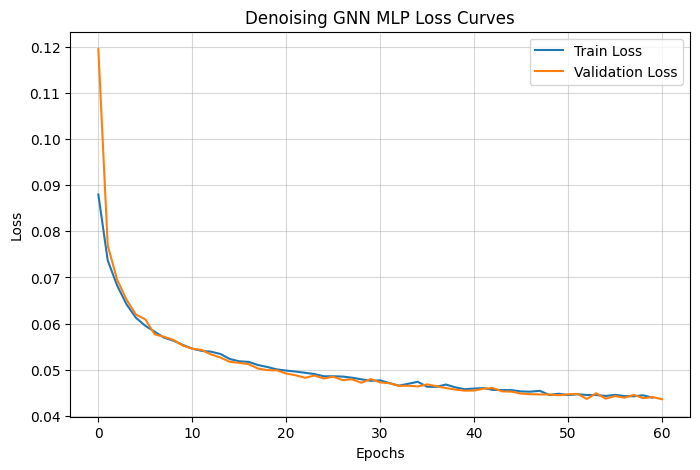

In [16]:
plot_loss_curves(loss_history_traj.train_loss, loss_history_traj.val_loss, title="Denoising GNN MLP Loss Curves")

### Baseline: one-step autoregressive flow matching

To see what time bundling gains, we compare it with the one-step autoregressive flow matching model from before. That model was trained on the coarser trajectories (every 6th frame), so we first **retrain it on the finer trajectories** (every 2nd frame). The architecture and training procedure stay exactly the same.

For a fair comparison, both models start from the same point. The one-step model starts its rollout from the last observed frame ($t = 5$) and then generates the remaining 13 frames one at a time, just as the bundled model generates them in one call. For both models we draw 10 samples per initial condition.

In [17]:
step_fine_module = GraphDataModule(dataset=gravity_step_dataset, batch_size=16, train_split=0.7, val_split=0.1)
traj_fine_module = GraphDataModule(dataset=gravity_dataset, batch_size=16, train_split=0.7, val_split=0.1, inference_batch_size=256)

denoising_gnn_fine = DenoisingGNN(input_dim=target_dim, tau_dim=tau_dim, cond_dim=state_dim, hidden_dim=hidden_dim, output_dim=target_dim, in_edge_features=edge_feats_dim)
generative_model_fine = ProbabilisticParticleModel(model=denoising_gnn_fine, denoising_steps=20, learning_rate=5e-4, t_start=5, num_samples=20)

trainer4 = L.Trainer(max_epochs=50, accelerator="auto", limit_train_batches=300, limit_val_batches=100, logger=False, enable_checkpointing=False)
trainer4.fit(generative_model_fine, datamodule=step_fine_module)

rollouts_auto_fine = trainer4.predict(generative_model_fine, datamodule=traj_fine_module)
predicted_positions_auto_fine = T.cat(rollouts_auto_fine, dim=0).transpose(2,3).numpy()[..., :3]

ground_truth_auto_fine = [to_dense_batch(sample.x, sample.batch)[0] for sample in traj_fine_module.predict_dataloader()]
ground_truth_positions_auto_fine = T.cat(ground_truth_auto_fine, dim=0).transpose(1,2).numpy()[..., :3]    
assert np.allclose(ground_truth_positions_auto_fine, ground_truth_positions), "Ground truth positions mismatch between auto and bundled datasets."

GPU available: True (cuda), used: True
TPU available: False, using: 0 TPU cores
💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]

  | Name  | Type         | Params | Mode  | FLOPs
-------------------------------------------------------
0 | model | DenoisingGNN | 61.4 K | train | 0    
-------------------------------------------------------
61.4 K    Trainable params
0         Non-trainable params
61.4 K    Total params
0.246     Total estimated model params size (MB)
28        Modules in train mode
0         Modules in eval mode
0         Total Flops


Sanity Checking: |          | 0/? [00:00<?, ?it/s]

Training: |          | 0/? [00:00<?, ?it/s]

Validation: |          | 0/? [00:00<?, ?it/s]

Validation: |          | 0/? [00:00<?, ?it/s]

...

Validation: |          | 0/? [00:00<?, ?it/s]

Validation: |          | 0/? [00:00<?, ?it/s]

Validation: |          | 0/? [00:00<?, ?it/s]

`Trainer.fit` stopped: `max_epochs=50` reached.
LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]


Predicting: |          | 0/? [00:00<?, ?it/s]

## Comparing the one-step and the time-bundled model

We evaluate both models with the same metrics as before, computed only on the 13 generated frames: ADE and FDE, best-of-20 ADE and FDE  and the distributions of velocity and acceleration. Both models are now generative, so unlike the earlier comparison with the deterministic model, their ADEs can be compared directly.

Keep the cost in mind as well. With $S$ Euler steps, the one-step model needs $13 \cdot S$ network evaluations to generate the 13 frames, while the bundled model needs only $S$.

Autoregressive GNN ADE: 0.9588, FDE: 1.9359, min 20 ADE: 0.4387, min 20 FDE: 1.0142
Trajectory GNN ADE: 1.1550, FDE: 2.0339, min 20 ADE: 0.5448, min 20 FDE: 1.0719


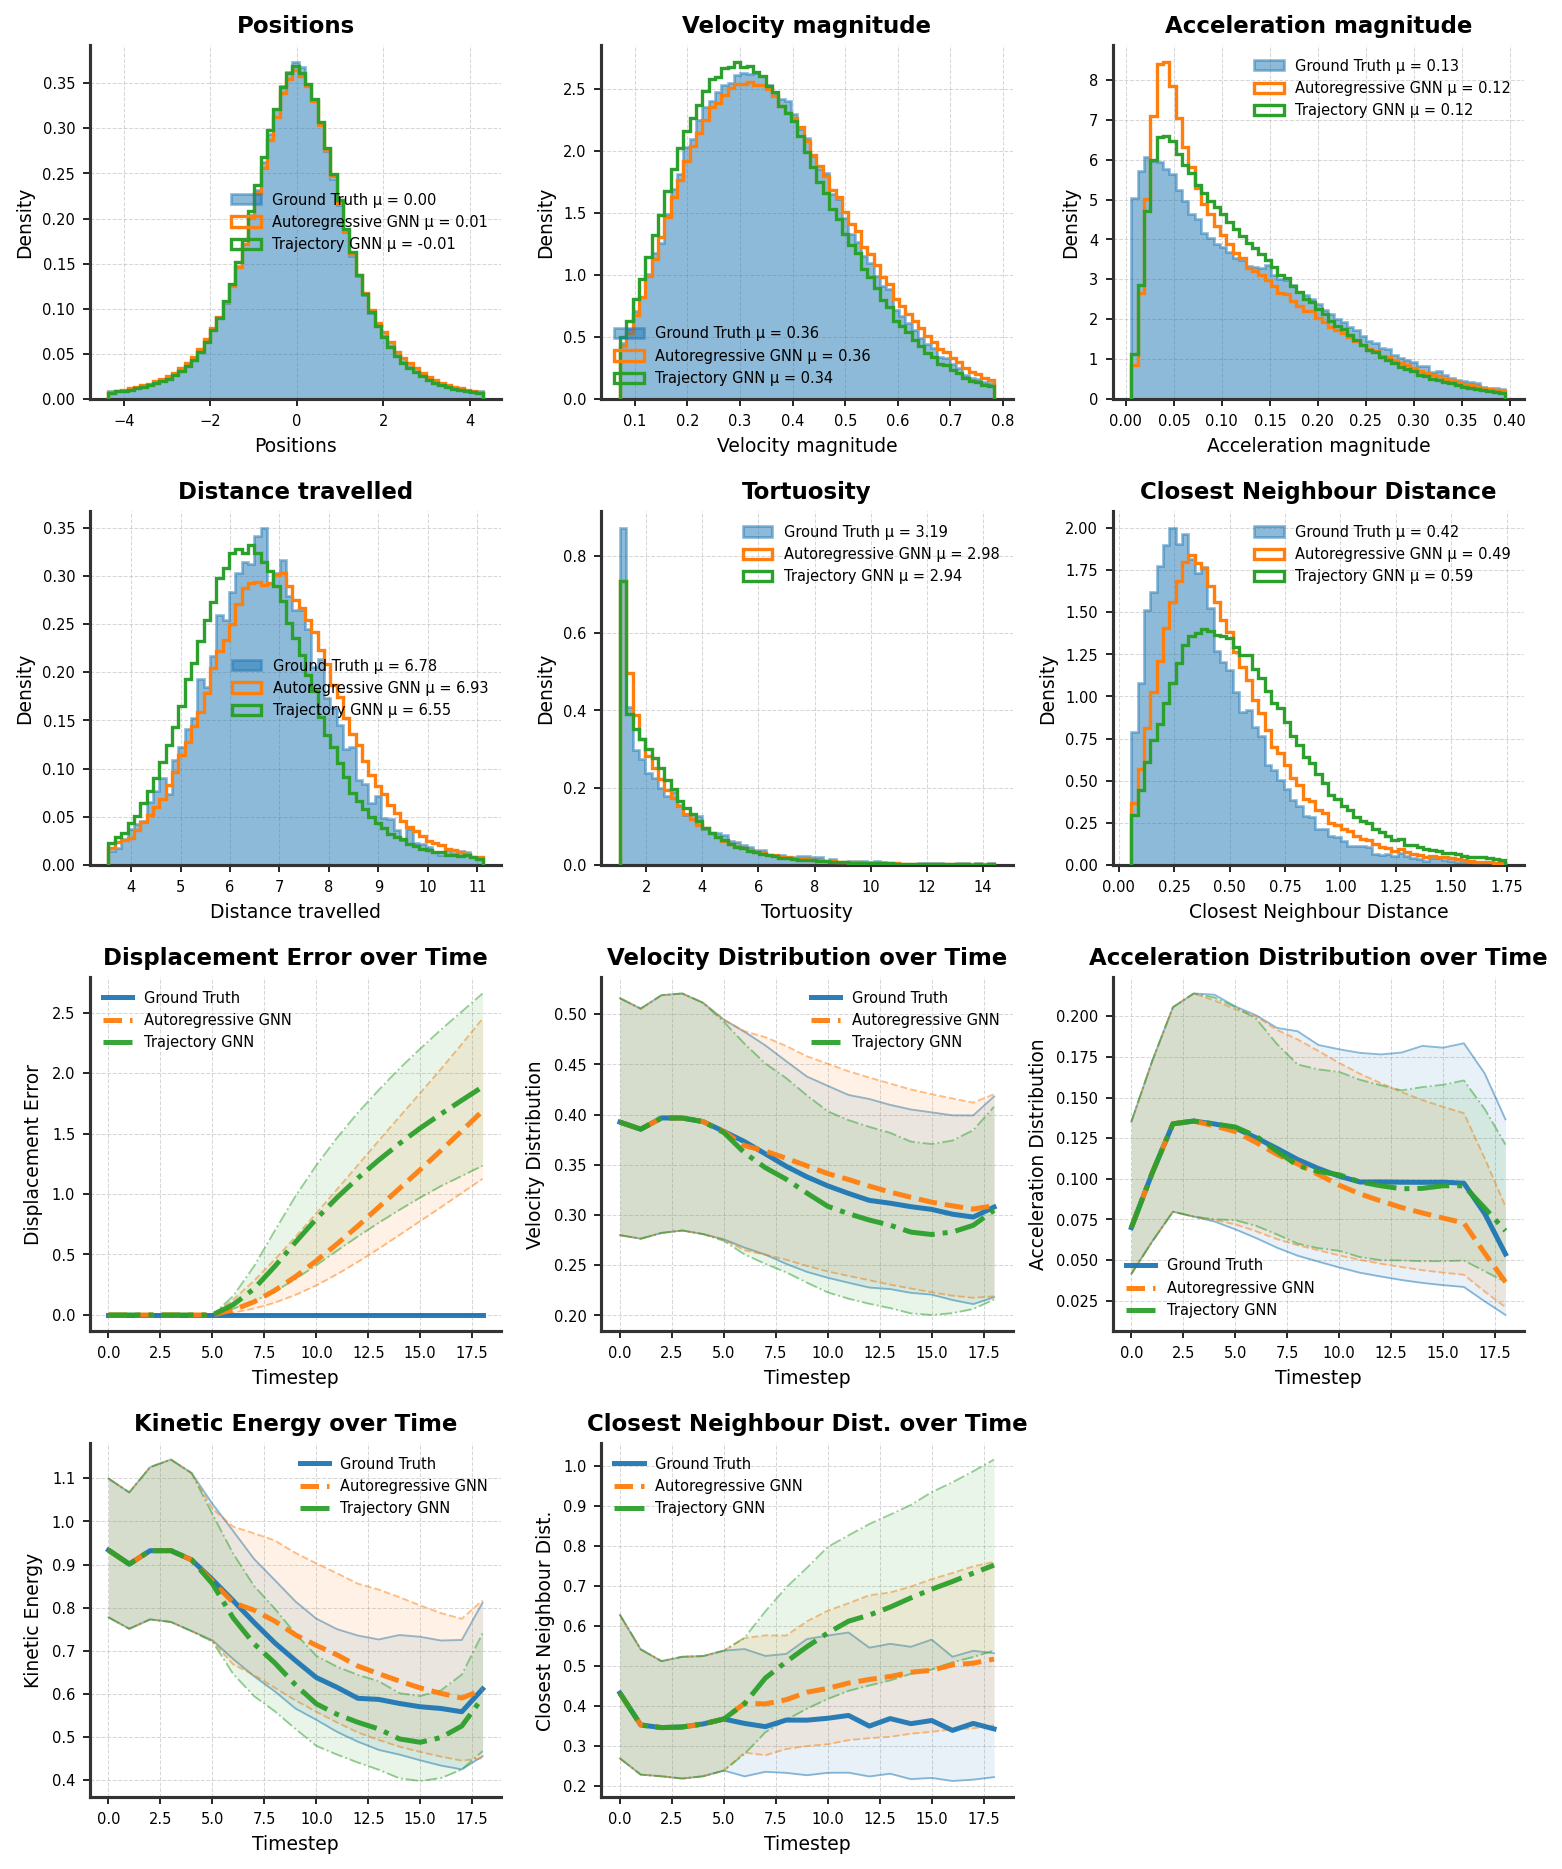

In [18]:
displacement_errors_auto = np.linalg.norm(predicted_positions_auto_fine - ground_truth_positions[:, None], axis=-1)
displacement_errors_traj = np.linalg.norm(predicted_positions_traj - ground_truth_positions[:, None], axis=-1)

ADE_auto = np.mean(displacement_errors_auto[:, :, H:], axis=(1,2))
FDE_auto = np.mean(displacement_errors_auto[:, :, -1], axis=(1))
ADE_traj = np.mean(displacement_errors_traj[:, :, H:], axis=(1,2))
FDE_traj = np.mean(displacement_errors_traj[:, :, -1], axis=(1))

S = displacement_errors_traj.shape[0]
best_auto = np.argmin(ADE_auto, axis=1)    
best_traj = np.argmin(ADE_traj, axis=1)    
best_errors_auto = displacement_errors_auto[np.arange(S), best_auto]     # (S, T, N)
best_errors_traj = displacement_errors_traj[np.arange(S), best_traj]     # (S, T, N)
min_20_ADE_auto = ADE_auto[np.arange(S), best_auto]
min_20_FDE_auto = np.min(FDE_auto, axis=1)
min_20_ADE_traj = ADE_traj[np.arange(S), best_traj]
min_20_FDE_traj = np.min(FDE_traj, axis=1)

print(f"Autoregressive GNN ADE: {np.mean(ADE_auto):.4f}, FDE: {np.mean(FDE_auto):.4f}, min 20 ADE: {np.mean(min_20_ADE_auto):.4f}, min 20 FDE: {np.mean(min_20_FDE_auto):.4f}")
print(f"Trajectory GNN ADE: {np.mean(ADE_traj):.4f}, FDE: {np.mean(FDE_traj):.4f}, min 20 ADE: {np.mean(min_20_ADE_traj):.4f}, min 20 FDE: {np.mean(min_20_FDE_traj):.4f}")

pred_auto_kin = calculate_kinematics(predicted_positions_auto_fine.reshape(-1, *predicted_positions_auto_fine.shape[2:]), dt)
pred_traj_kin = calculate_kinematics(predicted_positions_traj.reshape(-1, *predicted_positions_traj.shape[2:]), dt)
gt_kin = calculate_kinematics(ground_truth_positions, dt)


hist_names = ["Positions", "Velocity magnitude", "Acceleration magnitude", "Distance travelled", "Tortuosity", "Closest Neighbour Distance"]
hist_values = [(ground_truth_positions, predicted_positions_auto_fine.reshape(-1, *predicted_positions_auto_fine.shape[2:]), predicted_positions_traj.reshape(-1, *predicted_positions_traj.shape[2:])),
                (gt_kin['vel_magnitudes'], pred_auto_kin['vel_magnitudes'], pred_traj_kin['vel_magnitudes']),
                (gt_kin['acc_magnitudes'], pred_auto_kin['acc_magnitudes'], pred_traj_kin['acc_magnitudes']),
                (gt_kin['arc_lengths'], pred_auto_kin['arc_lengths'], pred_traj_kin['arc_lengths']),
                (gt_kin['tortuosity'], pred_auto_kin['tortuosity'], pred_traj_kin['tortuosity']),
                (gt_kin['closest_distances'], pred_auto_kin['closest_distances'], pred_traj_kin['closest_distances'])]
cmap = plt.get_cmap("tab10")
hist_colors = [(cmap(0), cmap(1), cmap(2)),
               (cmap(0), cmap(1), cmap(2)),
               (cmap(0), cmap(1), cmap(2)),
               (cmap(0), cmap(1), cmap(2)),
               (cmap(0), cmap(1), cmap(2)),
               (cmap(0), cmap(1), cmap(2))]

DE_auto = displacement_errors_auto.reshape(-1, *displacement_errors_auto.shape[2:])
DE_traj = displacement_errors_traj.reshape(-1, *displacement_errors_traj.shape[2:])

line_names = ["Displacement Error", "Velocity Distribution", "Acceleration Distribution", "Kinetic Energy", "Closest Neighbour Dist."]
line_values = [(np.zeros_like(DE_auto), DE_auto, DE_traj),
               (gt_kin['vel_magnitudes'], pred_auto_kin['vel_magnitudes'], pred_traj_kin['vel_magnitudes']),
               (gt_kin['acc_magnitudes'], pred_auto_kin['acc_magnitudes'], pred_traj_kin['acc_magnitudes']),
               (gt_kin['total_kinetic_energy'], pred_auto_kin['total_kinetic_energy'], pred_traj_kin['total_kinetic_energy']),
               (gt_kin['closest_distances'], pred_auto_kin['closest_distances'], pred_traj_kin['closest_distances'])]
line_colors = [(cmap(0), cmap(1), cmap(2)),
               (cmap(0), cmap(1), cmap(2)),
               (cmap(0), cmap(1), cmap(2)),
                (cmap(0), cmap(1), cmap(2)),
                (cmap(0), cmap(1), cmap(2))]

%matplotlib inline
whatever = plot_kinematics_summary(hist_values, hist_names, hist_colors,
                                    line_values, line_names, line_colors, model_labels=["Ground Truth", "Autoregressive GNN", "Trajectory GNN"]),

## **Question 2**
#### Even though time bundling needs a lot less inference time and on paper decreases rollout error accumulation, why does this model not perform much better?

## What are data couplings? How can we inform our prior?

So far, the prior samples $x_0$ and the targets $x_1$ were drawn independently. This is called the **independent coupling**:

$$\pi(x_0, x_1 \mid c) = p_0(x_0)\, p_1(x_1 \mid c), \qquad p_0 = \mathcal{N}(0, \sigma^2 I),$$

where $c$ is the condition: here, the observed frames $X^0, \dots, X^5$.

Flow matching does not require this. Any coupling $\pi(x_0, x_1)$ can be used, as long as we can still sample $x_0$ at inference. Take image restoration as an example: instead of starting from pure noise, the flow can start from the degraded image, which is already close to the clean target. When the prior samples lie closer to the targets, the paths from $x_0$ to $x_1$ are shorter and straighter. This makes the vector field easier to learn and allows fewer integration steps.

For our data, the observed frames carry information about the future motion. For example, the last observed velocity is a natural first guess for the next velocities. We can therefore use a **data-dependent coupling**, in which the prior depends on the condition:

$$\pi(x_0, x_1 \mid c) = p_0(x_0 \mid c)\, p_1(x_1 \mid c).$$

This factorization means the prior must be **conditionally independent** of the targets given the observed frames: $x_0 \perp x_1 \mid c$. In other words, the prior may only be built from the observed frames. The target frames are unavailable at inference, so a prior that uses them would leak information during training that the model can never access at test time.

## Flow matching with time bundling and an informed prior

### What makes a good prior?

In flow matching, every training pair $(x_0, x_1)$ is joined by a straight path, and the network learns to move along it. The expected squared length of these paths,

$$\mathcal{C}(p_0) = \mathbb{E}_{c}\,\mathbb{E}_{x_0 \sim p_0(\cdot \mid c),\; x_1 \sim p_1(\cdot \mid c)}\Big[\|x_0 - x_1\|^2\Big],$$

is the **transport cost** of the coupling we train with. A lower cost means shorter and straighter paths. That makes the vector field easier to learn and lets us use fewer Euler steps.

A zero-mean Gaussian ignores everything we already know, even though the observed frames tell us where each body is heading. We therefore want to **inform the prior with the observed frames**. A good informed prior $p_0(x_0 \mid c)$ balances three requirements:

1. **Close to the data.** The prior should already look like the future motion, so that $\mathcal{C}$ is small. The flow then only has to learn the *correction* from a physically sensible first guess to the true dynamics, instead of creating all the motion from nothing.
2. **Cheap to sample and built only from $c$.** We draw $x_0$ at every training step and at every inference call, so it must be fast. It may only use the observed frames: the targets are unknown at inference, and a prior that uses them would leak information during training ($x_0 \perp x_1 \mid c$).
3. **Random enough.** At inference, the noise in $x_0$ is the *only* source of randomness. A deterministic prior ($\sigma \to 0$) would make every rollout follow the same ODE path, giving one trajectory instead of a distribution. A prior that is too narrow forces the flow to stretch a tiny cloud into a wide distribution, which requires a steep vector field that is hard to learn.

These requirements pull against each other: less noise lowers the cost, but also removes diversity. We therefore keep the noise level fixed and only move the **mean** of the prior closer to the data. The mean is the part of the cost we can reduce without losing randomness.

### Setup for the time-bundled gravity data

As before, the model observes $H = 6$ frames and generates $K = 13$ frames in one call:

$$c = X^{0}, \dots, X^{5}, \qquad x_1 = \big(\mathbf{v}^{6}, \dots, \mathbf{v}^{18}\big).$$

All our priors have the same form, a mean built from $c$ plus Gaussian noise with the same scale as before, $\sigma^2 = 0.05$:

$$x_{0,i}^{k} = \boldsymbol{\mu}_i^{k}(c) + \sigma\,\boldsymbol{\epsilon}_i^{k}, \qquad \boldsymbol{\epsilon}_i^{k} \sim \mathcal{N}(0, I), \qquad k = 1, \dots, 13.$$

The uninformed prior uses $\boldsymbol{\mu}_i^{k} = \mathbf{0}$. The loss and the architecture stay exactly the same. Only the way $x_0$ is sampled changes, and it must be sampled in the same way during training and during inference.

### Example: a damped-velocity prior

The simplest informed guess is **constant velocity**, $\boldsymbol{\mu}_i^{k} = \mathbf{v}_i^{5}$: each body keeps moving as it did in the last observed frame. This works well for the first few frames. Further ahead, however, gravity bends the paths, and the future velocity has less and less to do with $\mathbf{v}_i^5$. A prior that trusts $\mathbf{v}_i^5$ equally for all 13 frames overshoots, and at later frames it can even be *further* from the data than the zero-mean prior.

We therefore trust the last observed velocity less the further we look ahead:

$$\boldsymbol{\mu}_i^{k} = \gamma^{k}\,\mathbf{v}_i^{5}, \qquad 0 \le \gamma \le 1.$$

For $\gamma = 1$ this is the constant-velocity prior, and for $\gamma = 0$ it is the uninformed prior. In between, the prior follows the observed motion at first and then gradually falls back to the zero-mean guess, which is the safe choice once the velocity is no longer predictable. We do not tune $\gamma$ by hand but fit it on the training data as the best one-step prediction $\mathbf{v}^{t+1} \approx \gamma\,\mathbf{v}^{t}$

**Let the kinematics choose the prior.** The best prior depends on how long the motion in the data "remembers" its velocity:

- If bodies move in nearly straight lines at nearly constant speed, the velocity stays predictable for a long time, $\gamma$ is close to $1$, and constant velocity is a strong prior.
- If forces change the velocity quickly, the velocity is quickly forgotten, $\gamma$ is smaller, and the prior should fall back to the zero-mean guess sooner. In our gravitational system this happens during close encounters and on strongly curved orbits.

It therefore pays to look at the data first. The velocity and acceleration distributions, the tortuosity and how quickly $\mathbf{v}^{t+k} \cdot \mathbf{v}^{t}$ decays with $k$ all tell us which prior is closest to the targets. In the next section we test this directly by measuring how far each prior is from the targets.

In [19]:
class InformedTrajectoryModel(ProbabilisticTrajectoryModel):
    def __init__(self, model, denoising_steps=10, learning_rate=1e-3, H=6, K=14, num_samples=10):
        super().__init__(model, denoising_steps, learning_rate, H, K, num_samples)

    def sample_prior(self, shape, X_H):
        """Sample from prior distribution informed by observed velocities."""
        last_velocity = X_H[:, -1:, 3:6]  # Get the last observed velocities (B*N, 3)
        informed_prior = last_velocity + math.sqrt(0.05) * T.randn(shape, device=X_H.device)  
        return informed_prior

class DampedVelocityTrajectoryModel(ProbabilisticTrajectoryModel):
    def __init__(self, model, gamma, denoising_steps=10, learning_rate=1e-3, H=6, K=13, num_samples=10):
        super().__init__(model, denoising_steps, learning_rate, H, K, num_samples)
        self.gamma = gamma  # how much of the velocity survives one frame (1 = constant velocity, 0 = zero-mean prior)

    def sample_prior(self, shape, X_H):
        """Last observed velocity, trusted less and less the further we look ahead: gamma^k * v^5 + noise."""
        last_velocity = X_H[:, -1:, 3:6]                                             # (B*N, 1, 3)
        k = T.arange(1, shape[1] + 1, device=X_H.device).view(1, -1, 1)              # (1, K, 1): 1, 2, ..., K
        return self.gamma ** k * last_velocity + math.sqrt(0.05) * T.randn(shape, device=X_H.device)


# Estimate gamma from the training data: the best fit of v^{t+1} ≈ gamma * v^t
v = T.stack([sample.x[..., 3:6] for sample in trajectory_bundled_datamodule.train_set])   # (S, N, T, 3)
gamma = ((v[:, :, 1:] * v[:, :, :-1]).sum() / (v[:, :, :-1] ** 2).sum()).item()
print(f"gamma = {gamma:.3f}  ->  after {K} frames, {gamma ** K:.0%} of the last velocity is kept")

damped_model = DampedVelocityTrajectoryModel(
    model=DenoisingGNNMLP(H=H, K=K, d=d, tau_dim=tau_dim, edge_dim=4, n_layers=n_layers, d_output=3),
    gamma=gamma, denoising_steps=20, learning_rate=5e-4, H=H, K=K, num_samples=20)

gamma = 0.809  ->  after 13 frames, 6% of the last velocity is kept


Transport cost E||x_0 - x_1||^2 per body on 1000 test scenes (noise floor 3Kσ² = 1.95)
prior                  total  total - floor    frame k=1    frame k=7   frame k=13
Uninformed             3.896          1.946       0.3395       0.2911       0.2818
Damped velocity        3.696          1.746       0.2110       0.2949       0.2819


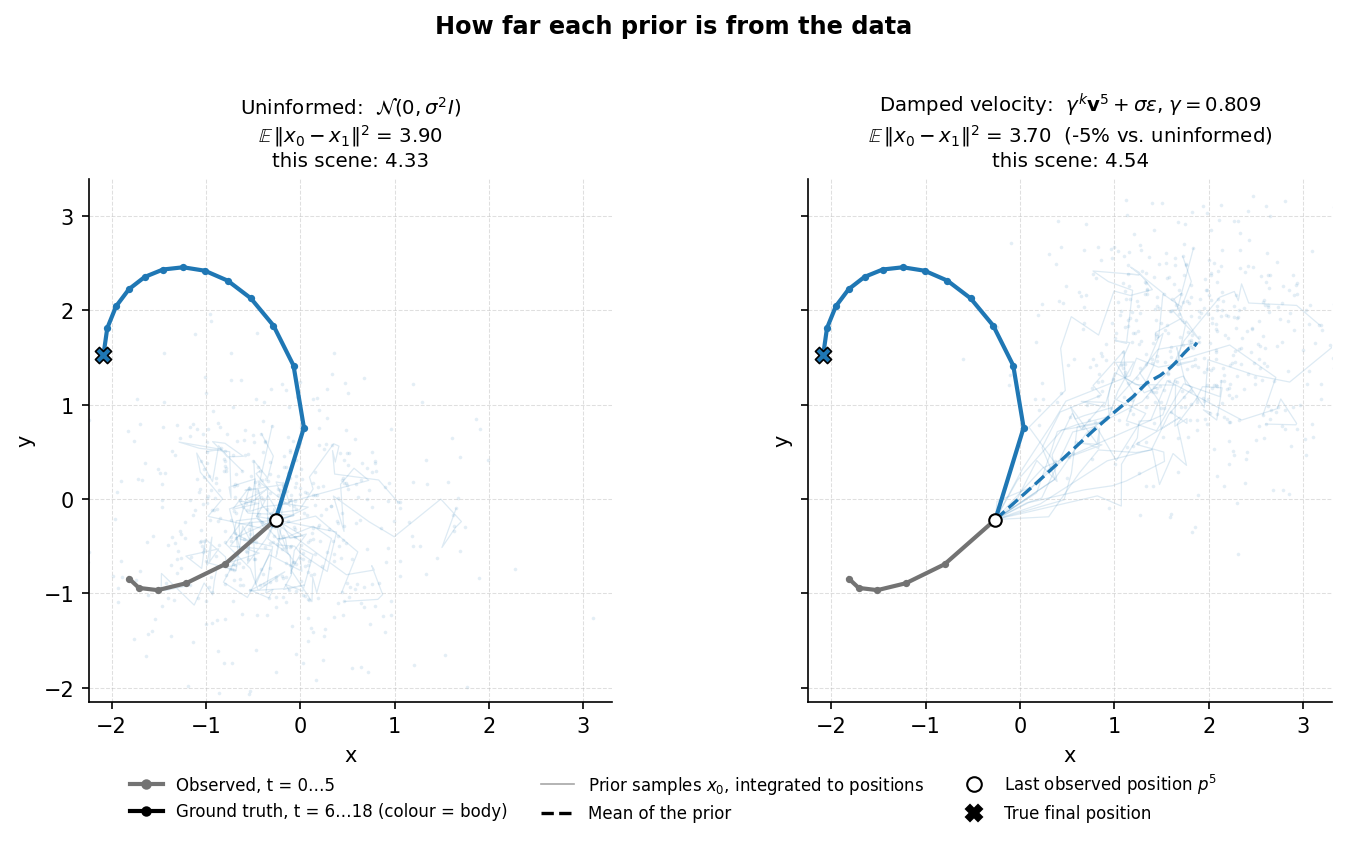

In [20]:
from types import SimpleNamespace
from matplotlib.lines import Line2D


def transport_cost(x0, x1):
    """Monte Carlo estimate of E||x_0 - x_1||^2 per body under the coupling used in training.

    x0: (M, B, K, 3) prior draws, x1: (B, K, 3) target velocities.
    Returns the total over all K frames and the contribution of every frame, (K,).
    """
    per_frame = ((x0 - x1[None]) ** 2).sum(axis=-1).mean(axis=(0, 1))    # (K,)
    return per_frame.sum(), per_frame


def plot_prior_comparison(scene, prior_draws, test_costs, H, noise_floor=None, bodies=None,
                          projection=(0, 1), n_samples_shown=15, title=None):
    """
    One panel per prior: the observed frames of one scene, followed by prior samples x_0 integrated
    to positions exactly like the model does, p^{H-1+k} = p^{H-1} + sum_{j<=k} x_0^j.

    scene:        (N, H+K, 6) ground-truth positions and velocities of one scene
    prior_draws:  {name: (formula, (M, N, K, 3) prior velocity draws for this scene)}
    test_costs:   {name: (total cost, per-frame cost)} over the whole test set, see transport_cost
    noise_floor:  3 K sigma^2, the part of the cost every prior pays because of its noise
    bodies:       bodies to draw (default: all)
    projection:   pair of axes to project onto, e.g. (0, 1) for the x-y plane
    """
    names = list(prior_draws)
    pos, v_target = scene[..., :3], scene[:, H:, 3:6]                   # (N, H+K, 3), (N, K, 3)
    N = pos.shape[0]
    bodies = np.arange(N) if bodies is None else np.asarray(bodies)
    a, b = projection
    colors = plt.get_cmap("tab10")(np.arange(N) % 10)
    p_last = pos[:, H - 1]                                              # last observed positions (N, 3)
    ref_cost = test_costs[names[0]][0]

    fig, axs = plt.subplots(1, len(names), figsize=(5.0 * len(names), 5.6), dpi=150,
                            sharex=True, sharey=True, squeeze=False)
    must_see = [pos[bodies][..., [a, b]].reshape(-1, 2)]               # observed + ground truth
    sample_pts = []

    for ax, name in zip(axs[0], names):
        formula, x0 = prior_draws[name]                                 # (M, N, K, 3)
        M = len(x0)
        start = np.broadcast_to(p_last[None, :, None], (M, N, 1, 3))
        paths = np.concatenate([start, start + np.cumsum(x0, axis=2)], axis=2)   # (M, N, K+1, 3)
        mean_path = paths.mean(axis=0)                                  # (N, K+1, 3)
        scene_cost, _ = transport_cost(x0, v_target)

        for n in bodies:
            c = colors[n]
            for m in range(min(n_samples_shown, M)):                    # individual prior samples
                ax.plot(paths[m, n, :, a], paths[m, n, :, b], color=c, alpha=0.15, lw=0.6, zorder=1)
            ax.scatter(paths[:, n, -1, a], paths[:, n, -1, b], color=c, s=3, alpha=0.12, lw=0, zorder=1)
            ax.plot(mean_path[n, :, a], mean_path[n, :, b], color=c, ls="--", lw=1.6, zorder=3)
            ax.plot(pos[n, :H, a], pos[n, :H, b], color="0.45", lw=2.0, marker="o", ms=3.5, mew=0, zorder=4)
            ax.plot(pos[n, H - 1:, a], pos[n, H - 1:, b], color=c, lw=2.0, marker="o", ms=3.5, mew=0, zorder=4)
            ax.scatter(*p_last[n, [a, b]], color="white", edgecolor="black", s=36, lw=1.0, zorder=5)
            ax.scatter(*pos[n, -1, [a, b]], color=c, edgecolor="black", marker="X", s=60, lw=0.8, zorder=6)
        sample_pts.append(paths[:, bodies][..., [a, b]].reshape(-1, 2))

        cost = test_costs[name][0]
        rel = "" if name == names[0] else f"  ({cost / ref_cost - 1:+.0%} vs. {names[0].lower()})"
        ax.set_title(f"{name}:  {formula}\n"
                     + r"$\mathbb{E}\,\|x_0 - x_1\|^2$" + f" = {cost:.2f}{rel}\n"
                     + f"this scene: {scene_cost:.2f}", fontsize=9.5)
        ax.set_xlabel("xyz"[a]); ax.set_ylabel("xyz"[b])
        ax.grid(alpha=0.4, ls="--", lw=0.5)
        ax.spines[["top", "right"]].set_visible(False)

    # Shared square view: all observed / true points, and the central 98% of the prior samples
    core = np.concatenate(must_see)
    samples = np.concatenate(sample_pts)
    lo = np.minimum(core.min(axis=0), np.percentile(samples, 1, axis=0))
    hi = np.maximum(core.max(axis=0), np.percentile(samples, 99, axis=0))
    centre, half = (lo + hi) / 2, 0.53 * (hi - lo).max()
    for ax in axs[0]:
        ax.set_xlim(centre[0] - half, centre[0] + half); ax.set_ylim(centre[1] - half, centre[1] + half)
        ax.set_aspect("equal", adjustable="box")

    K = scene.shape[1] - H
    handles = [
        Line2D([], [], color="0.45", lw=2, marker="o", ms=4),
        Line2D([], [], color="black", lw=2, marker="o", ms=4),
        Line2D([], [], color="black", lw=0.8, alpha=0.35),
        Line2D([], [], color="black", lw=1.6, ls="--"),
        Line2D([], [], color="white", marker="o", markeredgecolor="black", ls="", ms=7),
        Line2D([], [], color="black", marker="X", markeredgecolor="black", ls="", ms=8),
    ]
    labels = [f"Observed, t = 0…{H - 1}", f"Ground truth, t = {H}…{H + K - 1} (colour = body)",
              "Prior samples $x_0$, integrated to positions", "Mean of the prior",
              f"Last observed position $p^{{{H - 1}}}$", "True final position"]
    fig.legend(handles, labels, loc="lower center", bbox_to_anchor=(0.5, 0.0), ncol=3, fontsize=8, frameon=False)

    fig.suptitle((title or "How far each prior is from the data"), fontsize=11.5, fontweight="bold")
    fig.tight_layout(rect=(0, 0.13, 1, 0.9))
    return fig


@T.no_grad()
def draw_prior(prior_fn, X_H, K, M, seed=0):
    """M prior draws for every body. X_H: (B, H, 6) observed frames -> (M, B, K, 3) numpy array."""
    T.manual_seed(seed)
    X_rep = X_H.repeat(M, 1, 1)                                         # (M*B, H, 6)
    x0 = prior_fn((X_rep.shape[0], K, 3), X_rep)
    return x0.reshape(M, X_H.shape[0], K, 3).cpu().numpy()

sigma2 = 0.05
priors = {   # name: (formula for the title, sample_prior(shape, X_H))
    "Uninformed": (r"$\mathcal{N}(0,\sigma^2 I)$",
                   lambda shape, X_H: ProbabilisticTrajectoryModel.sample_prior(None, shape, X_H)),
    "Damped velocity": (rf"$\gamma^k\mathbf{{v}}^5 + \sigma\epsilon$, $\gamma = {gamma:.3f}$",
                        lambda shape, X_H: DampedVelocityTrajectoryModel.sample_prior(
                            SimpleNamespace(gamma=gamma), shape, X_H)),
}

# Transport cost over the whole test set
test_X = T.stack([s.x for s in trajectory_bundled_datamodule.test_set])   # (S, N, H+K, 6)
X_H_test = test_X[:, :, :H].reshape(-1, H, 6)                             # (S*N, H, 6)
x1_test = test_X[:, :, H:H + K, 3:6].reshape(-1, K, 3).numpy()            # (S*N, K, 3)
test_costs = {name: transport_cost(draw_prior(fn, X_H_test, K, M=10), x1_test)
              for name, (_, fn) in priors.items()}
noise_floor = 3 * K * sigma2

ks = [1, (K + 1) // 2, K]
print(f"Transport cost E||x_0 - x_1||^2 per body on {len(test_X)} test scenes (noise floor 3Kσ² = {noise_floor:.2f})")
print(f"{'prior':<20}{'total':>8}{'total - floor':>15}" + "".join(f"{f'frame k={k}':>13}" for k in ks))
for name, (total, per_frame) in test_costs.items():
    print(f"{name:<20}{total:>8.3f}{total - noise_floor:>15.3f}" + "".join(f"{per_frame[k - 1]:>13.4f}" for k in ks))

# One test scene: observed frames followed by the three priors
scene_idx = 0
scene = test_X[scene_idx]                                                   # (N, H+K, 6)
scene_draws = {name: (formula, draw_prior(fn, scene[:, :H], K, M=500))
               for name, (formula, fn) in priors.items()}

%matplotlib inline
fig = plot_prior_comparison(scene.numpy(), scene_draws, test_costs, H=H, noise_floor=noise_floor,
                            bodies=[0], projection=(0, 1), n_samples_shown=15)
fig.savefig("figures/prior_transport_cost.png", dpi=300, bbox_inches="tight")
plt.show()

![SegmentLocal](figures/denoising_informed_no_vectors.gif)

![SegmentLocal](figures/denoising_informed.gif)

## Summary: lessons from this practical

1. **Chaos calls for distributions.** In a chaotic system, tiny errors grow exponentially, so the future is best described by a distribution of plausible trajectories rather than a single prediction.
2. **MSE predicts the average.** A model trained with the MSE loss learns the conditional mean $\mathbb{E}[V^{t+1} \mid X^t]$, which blends all possible futures into an over-smoothed trajectory that no physical system would follow.
3. **Flow matching generates sharp futures.** A flow matching model learns the full conditional distribution $p(V^{t+1} \mid X^t)$ and draws distinct, realistic samples, with new noise giving a new plausible future on every rollout.
4. **Low ADE/FDE is not the goal on its own.** Pointwise errors favour the "safe" average, so generative models should also be judged with best-of-$M$ metrics and by how well their kinematic distributions (speeds, accelerations, distances, energy) match the data.
5. **A perturbed simulator is the reference for uncertainty.** Rerunning the real simulator from slightly perturbed initial states shows the true spread of futures, which we can compare directly with the spread of the model's samples.
6. **Time resolution shapes the one-step uncertainty.** With finer frames, less can happen between two frames, so $p(V^{t+1} \mid X^t)$ becomes narrower, even though the uncertainty over the full trajectory still grows through chaos.
7. **Time bundling reduces calls and error accumulation.** Generating $K$ frames per call cuts the number of sequential model calls, and thus the chances for errors to feed back, by a factor of $K$, and reduces inference cost accordingly.
8. **Bundling needs a model of time.** Flattening the window into an MLP ignores temporal order and relies on the bodies' positions at a single frame, which limits how much time bundling can gain.
9. **Bundling needs more information from edges** As the model receives multiple frames as input, node information might need to be recalculated to provide edge features on the whole trajectory 
9. **The prior does not have to be pure noise.** Flow matching works with any coupling $\pi(x_0, x_1 \mid c)$, as long as the prior uses only the observed frames and is sampled in the same way during training and inference.
10. **Informed priors lower the transport cost.** A prior whose mean lies closer to the targets gives shorter, straighter paths, which makes the vector field easier to learn and allows fewer integration steps.
11. **The prior must stay random.** The noise in $x_0$ is the only source of randomness at inference, so we lower the transport cost by moving the mean of the prior while keeping its noise.
12. **Let the data choose the prior.** How long velocities stay correlated in the data decides how far ahead we can trust the last observed velocity: long correlations favour constant velocity, short ones favour a damped velocity or even the zero-mean prior.

# Assignment 2 Dataset: Pedestrians on Eindhoven Centraal Train Station

![SegmentLocal](figures/pedestrian_trajectories.gif)